# Main

In [53]:
%pip install scikit_posthocs

In [54]:
import ast
import re
import os
import numpy as np
import pandas as pd
from scipy import stats
import scikit_posthocs as sp
import seaborn as sns
import matplotlib.pyplot as plt

In [55]:
files_list = os.listdir("/content/drive/MyDrive/Colab Notebooks/output/statistics/")
files_list

['sampled_all_systems.csv',
 'concat_flaml.csv',
 'concat_ag.csv',
 'result_monotonic_llama.csv',
 'result_monotonic_mistral.csv',
 'llama.csv',
 'mistral.csv',
 'result_equal_monotonic_ag_equal.csv',
 'result_monotonic_ag_equal.csv',
 'result_equal_monotonic_flaml_equal.csv',
 'result_monotonic_flaml_equal.csv',
 'result_equal_monotonic_rf_equal.csv',
 'result_monotonic_rf_equal.csv',
 'old_concat_rf.csv',
 'old_hpo_all_systems.csv',
 'concat_rf.csv',
 'hpo_all_systems.csv']

In [56]:
def non_empty_stringified_list(string: str) -> bool:
    try:
        value = ast.literal_eval(string)
        if value or len(value) > 0:
            return True
        return False
    except:
        return False

def has_missed_labels(string: str) -> bool:
    return non_empty_stringified_list(string)

def did_hallucinate(string: str) -> bool:
    return non_empty_stringified_list(string)

def is_better_than_dummy(row: pd.Series) -> bool:
    if row["hold_out_f1_score"] > row["f1_micro_majority"]:
        return True
    return False

In [57]:
# drop all the datasets that used sd_02 so that it is possible to calculate considering all the methods --- or consider only the 41 datasets that appear in the concat case


# use everything based on the predicted dataset

# concat case:

# autogluon - separate for each percentage after
automl_concat_ag_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_ag.csv", sep=";")
# automl_concat_ag_df["are_concat_pred_equal"] = automl_concat_ag_df.apply(lambda row: row["concatenated_dataset"] == row["predicted_dataset"], axis=1)
# equal_concat_ag_df = automl_concat_ag_df[automl_concat_ag_df["are_concat_pred_equal"]]
# diff_concat_ag_df = automl_concat_ag_df[~(automl_concat_ag_df["are_concat_pred_equal"])]

adapt_mask = automl_concat_ag_df["concatenated_dataset"] == automl_concat_ag_df["predicted_dataset"]
aug_mask = automl_concat_ag_df["trained_dataset"] == automl_concat_ag_df["predicted_dataset"]

equal_concat_ag_df = automl_concat_ag_df.loc[adapt_mask & (~aug_mask)]
diff_concat_ag_df = automl_concat_ag_df.loc[(~adapt_mask) & (~aug_mask)]


grouped_equal_concat_ag_df = equal_concat_ag_df.groupby(["predicted_dataset","automl_system", "method", "percentage"], as_index=False).agg(
    mean_hold_out_equal_ag_concat=('hold_out_f1_score', 'mean'),
    min_hold_out_equal_ag_concat=('hold_out_f1_score', 'min'),
    max_hold_out_equal_ag_concat=('hold_out_f1_score', 'max')
)
grouped_equal_concat_ag_df_25 = grouped_equal_concat_ag_df[grouped_equal_concat_ag_df["percentage"]==25][["predicted_dataset", "mean_hold_out_equal_ag_concat", "min_hold_out_equal_ag_concat", "max_hold_out_equal_ag_concat"]]
grouped_equal_concat_ag_df_25 = grouped_equal_concat_ag_df_25.rename(columns={"mean_hold_out_equal_ag_concat": "mean_hold_out_equal_ag_concat_25", "min_hold_out_equal_ag_concat": "min_hold_out_equal_ag_concat_25", "max_hold_out_equal_ag_concat": "max_hold_out_equal_ag_concat_25"})
grouped_equal_concat_ag_df_25["min_max_equal_ag_concat_25"] = grouped_equal_concat_ag_df_25.apply(lambda row: row["max_hold_out_equal_ag_concat_25"] - row["min_hold_out_equal_ag_concat_25"], axis=1)
grouped_equal_concat_ag_df_50 = grouped_equal_concat_ag_df[grouped_equal_concat_ag_df["percentage"]==50][["predicted_dataset", "mean_hold_out_equal_ag_concat", "min_hold_out_equal_ag_concat", "max_hold_out_equal_ag_concat"]]
grouped_equal_concat_ag_df_50 = grouped_equal_concat_ag_df_50.rename(columns={"mean_hold_out_equal_ag_concat": "mean_hold_out_equal_ag_concat_50", "min_hold_out_equal_ag_concat": "min_hold_out_equal_ag_concat_50", "max_hold_out_equal_ag_concat": "max_hold_out_equal_ag_concat_50"})
grouped_equal_concat_ag_df_50["min_max_equal_ag_concat_50"] = grouped_equal_concat_ag_df_50.apply(lambda row: row["max_hold_out_equal_ag_concat_50"] - row["min_hold_out_equal_ag_concat_50"], axis=1)
grouped_equal_concat_ag_df_75 = grouped_equal_concat_ag_df[grouped_equal_concat_ag_df["percentage"]==75][["predicted_dataset", "mean_hold_out_equal_ag_concat", "min_hold_out_equal_ag_concat", "max_hold_out_equal_ag_concat"]]
grouped_equal_concat_ag_df_75 = grouped_equal_concat_ag_df_75.rename(columns={"mean_hold_out_equal_ag_concat": "mean_hold_out_equal_ag_concat_75", "min_hold_out_equal_ag_concat": "min_hold_out_equal_ag_concat_75", "max_hold_out_equal_ag_concat": "max_hold_out_equal_ag_concat_75"})
grouped_equal_concat_ag_df_75["min_max_equal_ag_concat_75"] = grouped_equal_concat_ag_df_75.apply(lambda row: row["max_hold_out_equal_ag_concat_75"] - row["min_hold_out_equal_ag_concat_75"], axis=1)

grouped_diff_concat_ag_df = diff_concat_ag_df.groupby(["predicted_dataset","automl_system", "method", "percentage"], as_index=False).agg(mean_hold_out_diff_ag_concat=('hold_out_f1_score', 'mean'),
    min_hold_out_diff_ag_concat=('hold_out_f1_score', 'min'),
    max_hold_out_diff_ag_concat=('hold_out_f1_score', 'max')
)
# grouped_diff_concat_ag_df = grouped_diff_concat_ag_df.rename(columns={"mean_hold_out_diff_ag_concat": "mean_hold_out_diff_ag_concat_25", "min_hold_out_diff_ag_concat": "min_hold_out_diff_ag_concat_25", "max_hold_out_diff_ag_concat": "max_hold_out_diff_ag_concat_25"})
grouped_diff_concat_ag_df_25 = grouped_diff_concat_ag_df[grouped_diff_concat_ag_df["percentage"]==25][["predicted_dataset", "mean_hold_out_diff_ag_concat", "min_hold_out_diff_ag_concat", "max_hold_out_diff_ag_concat"]]
grouped_diff_concat_ag_df_25 = grouped_diff_concat_ag_df_25.rename(columns={"mean_hold_out_diff_ag_concat": "mean_hold_out_diff_ag_concat_25", "min_hold_out_diff_ag_concat": "min_hold_out_diff_ag_concat_25", "max_hold_out_diff_ag_concat": "max_hold_out_diff_ag_concat_25"})
grouped_diff_concat_ag_df_25["min_max_diff_ag_concat_25"] = grouped_diff_concat_ag_df_25.apply(lambda row: row["max_hold_out_diff_ag_concat_25"] - row["min_hold_out_diff_ag_concat_25"], axis=1)
grouped_diff_concat_ag_df_50 = grouped_diff_concat_ag_df[grouped_diff_concat_ag_df["percentage"]==50][["predicted_dataset", "mean_hold_out_diff_ag_concat", "min_hold_out_diff_ag_concat", "max_hold_out_diff_ag_concat"]]
grouped_diff_concat_ag_df_50 = grouped_diff_concat_ag_df_50.rename(columns={"mean_hold_out_diff_ag_concat": "mean_hold_out_diff_ag_concat_50", "min_hold_out_diff_ag_concat": "min_hold_out_diff_ag_concat_50", "max_hold_out_diff_ag_concat": "max_hold_out_diff_ag_concat_50"})
grouped_diff_concat_ag_df_50["min_max_diff_ag_concat_50"] = grouped_diff_concat_ag_df_50.apply(lambda row: row["max_hold_out_diff_ag_concat_50"] - row["min_hold_out_diff_ag_concat_50"], axis=1)
grouped_diff_concat_ag_df_75 = grouped_diff_concat_ag_df[grouped_diff_concat_ag_df["percentage"]==75][["predicted_dataset", "mean_hold_out_diff_ag_concat", "min_hold_out_diff_ag_concat", "max_hold_out_diff_ag_concat"]]
grouped_diff_concat_ag_df_75 = grouped_diff_concat_ag_df_75.rename(columns={"mean_hold_out_diff_ag_concat": "mean_hold_out_diff_ag_concat_75", "min_hold_out_diff_ag_concat": "min_hold_out_diff_ag_concat_75", "max_hold_out_diff_ag_concat": "max_hold_out_diff_ag_concat_75"})
grouped_diff_concat_ag_df_75["min_max_diff_ag_concat_75"] = grouped_diff_concat_ag_df_75.apply(lambda row: row["max_hold_out_diff_ag_concat_75"] - row["min_hold_out_diff_ag_concat_75"], axis=1)


# flaml
automl_concat_flaml_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_flaml.csv", sep=";")
# automl_concat_flaml_df["are_concat_pred_equal"] = automl_concat_flaml_df.apply(lambda row: row["concatenated_dataset"] == row["predicted_dataset"], axis=1)
# equal_concat_flaml_df = automl_concat_flaml_df[automl_concat_flaml_df["are_concat_pred_equal"]]
# diff_concat_flaml_df = automl_concat_flaml_df[~(automl_concat_flaml_df["are_concat_pred_equal"])]

adapt_mask = automl_concat_flaml_df["concatenated_dataset"] == automl_concat_flaml_df["predicted_dataset"]
aug_mask = automl_concat_flaml_df["trained_dataset"] == automl_concat_flaml_df["predicted_dataset"]

equal_concat_flaml_df = automl_concat_flaml_df.loc[adapt_mask & (~aug_mask)]
diff_concat_flaml_df = automl_concat_flaml_df.loc[(~adapt_mask) & (~aug_mask)]

grouped_equal_concat_flaml_df = equal_concat_flaml_df.groupby(["predicted_dataset","automl_system", "method", "percentage"], as_index=False).agg(
    mean_hold_out_equal_flaml_concat=('hold_out_f1_score', 'mean'),
    min_hold_out_equal_flaml_concat=('hold_out_f1_score', 'min'),
    max_hold_out_equal_flaml_concat=('hold_out_f1_score', 'max')
)
grouped_equal_concat_flaml_df_25 = grouped_equal_concat_flaml_df[grouped_equal_concat_flaml_df["percentage"]==25][["predicted_dataset", "mean_hold_out_equal_flaml_concat", "min_hold_out_equal_flaml_concat", "max_hold_out_equal_flaml_concat"]]
grouped_equal_concat_flaml_df_25 = grouped_equal_concat_flaml_df_25.rename(columns={"mean_hold_out_equal_flaml_concat": "mean_hold_out_equal_flaml_concat_25", "min_hold_out_equal_flaml_concat": "min_hold_out_equal_flaml_concat_25", "max_hold_out_equal_flaml_concat": "max_hold_out_equal_flaml_concat_25"})
grouped_equal_concat_flaml_df_25["min_max_equal_flaml_concat_25"] = grouped_equal_concat_flaml_df_25.apply(lambda row: row["max_hold_out_equal_flaml_concat_25"] - row["min_hold_out_equal_flaml_concat_25"], axis=1)
grouped_equal_concat_flaml_df_50 = grouped_equal_concat_flaml_df[grouped_equal_concat_flaml_df["percentage"]==50][["predicted_dataset", "mean_hold_out_equal_flaml_concat", "min_hold_out_equal_flaml_concat", "max_hold_out_equal_flaml_concat"]]
grouped_equal_concat_flaml_df_50 = grouped_equal_concat_flaml_df_50.rename(columns={"mean_hold_out_equal_flaml_concat": "mean_hold_out_equal_flaml_concat_50", "min_hold_out_equal_flaml_concat": "min_hold_out_equal_flaml_concat_50", "max_hold_out_equal_flaml_concat": "max_hold_out_equal_flaml_concat_50"})
grouped_equal_concat_flaml_df_50["min_max_equal_flaml_concat_50"] = grouped_equal_concat_flaml_df_50.apply(lambda row: row["max_hold_out_equal_flaml_concat_50"] - row["min_hold_out_equal_flaml_concat_50"], axis=1)
grouped_equal_concat_flaml_df_75 = grouped_equal_concat_flaml_df[grouped_equal_concat_flaml_df["percentage"]==75][["predicted_dataset", "mean_hold_out_equal_flaml_concat", "min_hold_out_equal_flaml_concat", "max_hold_out_equal_flaml_concat"]]
grouped_equal_concat_flaml_df_75 = grouped_equal_concat_flaml_df_75.rename(columns={"mean_hold_out_equal_flaml_concat": "mean_hold_out_equal_flaml_concat_75", "min_hold_out_equal_flaml_concat": "min_hold_out_equal_flaml_concat_75", "max_hold_out_equal_flaml_concat": "max_hold_out_equal_flaml_concat_75"})
grouped_equal_concat_flaml_df_75["min_max_equal_flaml_concat_75"] = grouped_equal_concat_flaml_df_75.apply(lambda row: row["max_hold_out_equal_flaml_concat_75"] - row["min_hold_out_equal_flaml_concat_75"], axis=1)

grouped_diff_concat_flaml_df = diff_concat_flaml_df.groupby(["predicted_dataset","automl_system", "method", "percentage"], as_index=False).agg(mean_hold_out_diff_flaml_concat=('hold_out_f1_score', 'mean'),
    min_hold_out_diff_flaml_concat=('hold_out_f1_score', 'min'),
    max_hold_out_diff_flaml_concat=('hold_out_f1_score', 'max')
)
# grouped_diff_concat_flaml_df = grouped_diff_concat_flaml_df.rename(columns={"mean_hold_out_diff_flaml_concat": "mean_hold_out_diff_flaml_concat_25", "min_hold_out_diff_flaml_concat": "min_hold_out_diff_flaml_concat_25", "max_hold_out_diff_flaml_concat": "max_hold_out_diff_flaml_concat_25"})
grouped_diff_concat_flaml_df_25 = grouped_diff_concat_flaml_df[grouped_diff_concat_flaml_df["percentage"]==25][["predicted_dataset", "mean_hold_out_diff_flaml_concat", "min_hold_out_diff_flaml_concat", "max_hold_out_diff_flaml_concat"]]
grouped_diff_concat_flaml_df_25 = grouped_diff_concat_flaml_df_25.rename(columns={"mean_hold_out_diff_flaml_concat": "mean_hold_out_diff_flaml_concat_25", "min_hold_out_diff_flaml_concat": "min_hold_out_diff_flaml_concat_25", "max_hold_out_diff_flaml_concat": "max_hold_out_diff_flaml_concat_25"})
grouped_diff_concat_flaml_df_25["min_max_diff_flaml_concat_25"] = grouped_diff_concat_flaml_df_25.apply(lambda row: row["max_hold_out_diff_flaml_concat_25"] - row["min_hold_out_diff_flaml_concat_25"], axis=1)
grouped_diff_concat_flaml_df_50 = grouped_diff_concat_flaml_df[grouped_diff_concat_flaml_df["percentage"]==50][["predicted_dataset", "mean_hold_out_diff_flaml_concat", "min_hold_out_diff_flaml_concat", "max_hold_out_diff_flaml_concat"]]
grouped_diff_concat_flaml_df_50 = grouped_diff_concat_flaml_df_50.rename(columns={"mean_hold_out_diff_flaml_concat": "mean_hold_out_diff_flaml_concat_50", "min_hold_out_diff_flaml_concat": "min_hold_out_diff_flaml_concat_50", "max_hold_out_diff_flaml_concat": "max_hold_out_diff_flaml_concat_50"})
grouped_diff_concat_flaml_df_50["min_max_diff_flaml_concat_50"] = grouped_diff_concat_flaml_df_50.apply(lambda row: row["max_hold_out_diff_flaml_concat_50"] - row["min_hold_out_diff_flaml_concat_50"], axis=1)
grouped_diff_concat_flaml_df_75 = grouped_diff_concat_flaml_df[grouped_diff_concat_flaml_df["percentage"]==75][["predicted_dataset", "mean_hold_out_diff_flaml_concat", "min_hold_out_diff_flaml_concat", "max_hold_out_diff_flaml_concat"]]
grouped_diff_concat_flaml_df_75 = grouped_diff_concat_flaml_df_75.rename(columns={"mean_hold_out_diff_flaml_concat": "mean_hold_out_diff_flaml_concat_75", "min_hold_out_diff_flaml_concat": "min_hold_out_diff_flaml_concat_75", "max_hold_out_diff_flaml_concat": "max_hold_out_diff_flaml_concat_75"})
grouped_diff_concat_flaml_df_75["min_max_diff_flaml_concat_75"] = grouped_diff_concat_flaml_df_75.apply(lambda row: row["max_hold_out_diff_flaml_concat_75"] - row["min_hold_out_diff_flaml_concat_75"], axis=1)


# random forest
automl_concat_rf_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_rf.csv", sep=";")
# automl_concat_rf_df["are_concat_pred_equal"] = automl_concat_rf_df.apply(lambda row: row["concatenated_dataset"] == row["predicted_dataset"], axis=1)
# equal_concat_rf_df = automl_concat_rf_df[automl_concat_rf_df["are_concat_pred_equal"]]
# diff_concat_rf_df = automl_concat_rf_df[~(automl_concat_rf_df["are_concat_pred_equal"])]

adapt_mask = automl_concat_rf_df["concatenated_dataset"] == automl_concat_rf_df["predicted_dataset"]
aug_mask = automl_concat_rf_df["trained_dataset"] == automl_concat_rf_df["predicted_dataset"]

equal_concat_rf_df = automl_concat_rf_df.loc[adapt_mask & (~aug_mask)]
diff_concat_rf_df = automl_concat_rf_df.loc[(~adapt_mask) & (~aug_mask)]

grouped_equal_concat_rf_df = equal_concat_rf_df.groupby(["predicted_dataset","automl_system", "method", "percentage"], as_index=False).agg(
    mean_hold_out_equal_rf_concat=('hold_out_f1_score', 'mean'),
    min_hold_out_equal_rf_concat=('hold_out_f1_score', 'min'),
    max_hold_out_equal_rf_concat=('hold_out_f1_score', 'max')
)
grouped_equal_concat_rf_df_25 = grouped_equal_concat_rf_df[grouped_equal_concat_rf_df["percentage"]==25][["predicted_dataset", "mean_hold_out_equal_rf_concat", "min_hold_out_equal_rf_concat", "max_hold_out_equal_rf_concat"]]
grouped_equal_concat_rf_df_25 = grouped_equal_concat_rf_df_25.rename(columns={"mean_hold_out_equal_rf_concat": "mean_hold_out_equal_rf_concat_25", "min_hold_out_equal_rf_concat": "min_hold_out_equal_rf_concat_25", "max_hold_out_equal_rf_concat": "max_hold_out_equal_rf_concat_25"})
grouped_equal_concat_rf_df_25["min_max_equal_rf_concat_25"] = grouped_equal_concat_rf_df_25.apply(lambda row: row["max_hold_out_equal_rf_concat_25"] - row["min_hold_out_equal_rf_concat_25"], axis=1)
grouped_equal_concat_rf_df_50 = grouped_equal_concat_rf_df[grouped_equal_concat_rf_df["percentage"]==50][["predicted_dataset", "mean_hold_out_equal_rf_concat", "min_hold_out_equal_rf_concat", "max_hold_out_equal_rf_concat"]]
grouped_equal_concat_rf_df_50 = grouped_equal_concat_rf_df_50.rename(columns={"mean_hold_out_equal_rf_concat": "mean_hold_out_equal_rf_concat_50", "min_hold_out_equal_rf_concat": "min_hold_out_equal_rf_concat_50", "max_hold_out_equal_rf_concat": "max_hold_out_equal_rf_concat_50"})
grouped_equal_concat_rf_df_50["min_max_equal_rf_concat_50"] = grouped_equal_concat_rf_df_50.apply(lambda row: row["max_hold_out_equal_rf_concat_50"] - row["min_hold_out_equal_rf_concat_50"], axis=1)
grouped_equal_concat_rf_df_75 = grouped_equal_concat_rf_df[grouped_equal_concat_rf_df["percentage"]==75][["predicted_dataset", "mean_hold_out_equal_rf_concat", "min_hold_out_equal_rf_concat", "max_hold_out_equal_rf_concat"]]
grouped_equal_concat_rf_df_75 = grouped_equal_concat_rf_df_75.rename(columns={"mean_hold_out_equal_rf_concat": "mean_hold_out_equal_rf_concat_75", "min_hold_out_equal_rf_concat": "min_hold_out_equal_rf_concat_75", "max_hold_out_equal_rf_concat": "max_hold_out_equal_rf_concat_75"})
grouped_equal_concat_rf_df_75["min_max_equal_rf_concat_75"] = grouped_equal_concat_rf_df_75.apply(lambda row: row["max_hold_out_equal_rf_concat_75"] - row["min_hold_out_equal_rf_concat_75"], axis=1)

grouped_diff_concat_rf_df = diff_concat_rf_df.groupby(["predicted_dataset","automl_system", "method", "percentage"], as_index=False).agg(mean_hold_out_diff_rf_concat=('hold_out_f1_score', 'mean'),
    min_hold_out_diff_rf_concat=('hold_out_f1_score', 'min'),
    max_hold_out_diff_rf_concat=('hold_out_f1_score', 'max')
)
# grouped_diff_concat_rf_df = grouped_diff_concat_rf_df.rename(columns={"mean_hold_out_diff_rf_concat": "mean_hold_out_diff_rf_concat_25", "min_hold_out_diff_rf_concat": "min_hold_out_diff_rf_concat_25", "max_hold_out_diff_rf_concat": "max_hold_out_diff_rf_concat_25"})
grouped_diff_concat_rf_df_25 = grouped_diff_concat_rf_df[grouped_diff_concat_rf_df["percentage"]==25][["predicted_dataset", "mean_hold_out_diff_rf_concat", "min_hold_out_diff_rf_concat", "max_hold_out_diff_rf_concat"]]
grouped_diff_concat_rf_df_25 = grouped_diff_concat_rf_df_25.rename(columns={"mean_hold_out_diff_rf_concat": "mean_hold_out_diff_rf_concat_25", "min_hold_out_diff_rf_concat": "min_hold_out_diff_rf_concat_25", "max_hold_out_diff_rf_concat": "max_hold_out_diff_rf_concat_25"})
grouped_diff_concat_rf_df_25["min_max_diff_rf_concat_25"] = grouped_diff_concat_rf_df_25.apply(lambda row: row["max_hold_out_diff_rf_concat_25"] - row["min_hold_out_diff_rf_concat_25"], axis=1)
grouped_diff_concat_rf_df_50 = grouped_diff_concat_rf_df[grouped_diff_concat_rf_df["percentage"]==50][["predicted_dataset", "mean_hold_out_diff_rf_concat", "min_hold_out_diff_rf_concat", "max_hold_out_diff_rf_concat"]]
grouped_diff_concat_rf_df_50 = grouped_diff_concat_rf_df_50.rename(columns={"mean_hold_out_diff_rf_concat": "mean_hold_out_diff_rf_concat_50", "min_hold_out_diff_rf_concat": "min_hold_out_diff_rf_concat_50", "max_hold_out_diff_rf_concat": "max_hold_out_diff_rf_concat_50"})
grouped_diff_concat_rf_df_50["min_max_diff_rf_concat_50"] = grouped_diff_concat_rf_df_50.apply(lambda row: row["max_hold_out_diff_rf_concat_50"] - row["min_hold_out_diff_rf_concat_50"], axis=1)
grouped_diff_concat_rf_df_75 = grouped_diff_concat_rf_df[grouped_diff_concat_rf_df["percentage"]==75][["predicted_dataset", "mean_hold_out_diff_rf_concat", "min_hold_out_diff_rf_concat", "max_hold_out_diff_rf_concat"]]
grouped_diff_concat_rf_df_75 = grouped_diff_concat_rf_df_75.rename(columns={"mean_hold_out_diff_rf_concat": "mean_hold_out_diff_rf_concat_75", "min_hold_out_diff_rf_concat": "min_hold_out_diff_rf_concat_75", "max_hold_out_diff_rf_concat": "max_hold_out_diff_rf_concat_75"})
grouped_diff_concat_rf_df_75["min_max_diff_rf_concat_75"] = grouped_diff_concat_rf_df_75.apply(lambda row: row["max_hold_out_diff_rf_concat_75"] - row["min_hold_out_diff_rf_concat_75"], axis=1)


# Llama
llama_output_results_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/llama.csv", sep=";")
zero_llama_output_results_df = llama_output_results_df[llama_output_results_df["number_of_examples"]==0]
zero_llama_output_results_df = zero_llama_output_results_df[["predicted_dataset","hold_out_f1_score"]]
zero_llama_output_results_df = zero_llama_output_results_df.rename(columns={"hold_out_f1_score":"llama_zero_shot_hold_out_f1_score"})
five_llama_output_results_df = llama_output_results_df[llama_output_results_df["number_of_examples"]==5]
five_llama_output_results_df = five_llama_output_results_df[["predicted_dataset","hold_out_f1_score"]]
five_llama_output_results_df = five_llama_output_results_df.rename(columns={"hold_out_f1_score":"llama_five_shot_hold_out_f1_score"})


# Mistral
mistral_output_results_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/mistral.csv", sep=";")
zero_mistral_output_results_df = mistral_output_results_df[mistral_output_results_df["number_of_examples"]==0]
zero_mistral_output_results_df = zero_mistral_output_results_df[["predicted_dataset","hold_out_f1_score"]]
zero_mistral_output_results_df = zero_mistral_output_results_df.rename(columns={"hold_out_f1_score":"mistral_zero_shot_hold_out_f1_score"})
five_mistral_output_results_df = mistral_output_results_df[mistral_output_results_df["number_of_examples"]==5]
five_mistral_output_results_df = five_mistral_output_results_df[["predicted_dataset","hold_out_f1_score"]]
five_mistral_output_results_df = five_mistral_output_results_df.rename(columns={"hold_out_f1_score":"mistral_five_shot_hold_out_f1_score"})







# HPO
automl_hpo_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/hpo_all_systems.csv", sep=";")
automl_hpo_df["are_trained_pred_equal"] = automl_hpo_df.apply(lambda row: row["trained_dataset"] == row["predicted_dataset"], axis=1)


automl_hpo_ag_df = automl_hpo_df[automl_hpo_df["automl_system"]=="AutoGluon"]
equal_hpo_ag_df = automl_hpo_ag_df[automl_hpo_ag_df["are_trained_pred_equal"]]
diff_hpo_ag_df = automl_hpo_ag_df[~(automl_hpo_ag_df["are_trained_pred_equal"])]

grouped_equal_hpo_ag_df = equal_hpo_ag_df.groupby(["predicted_dataset"], as_index=False).agg({"hold_out_f1_score": "mean"})
grouped_equal_hpo_ag_df = grouped_equal_hpo_ag_df.rename(columns={"hold_out_f1_score": "hold_out_equal_ag_hpo"})
grouped_diff_hpo_ag_df = diff_hpo_ag_df.groupby(["predicted_dataset"], as_index=False).agg({"hold_out_f1_score": "mean"})
grouped_diff_hpo_ag_df = grouped_diff_hpo_ag_df.rename(columns={"hold_out_f1_score": "hold_out_diff_ag_hpo"})

# flaml
automl_hpo_flaml_df = automl_hpo_df[automl_hpo_df["automl_system"]=="FLAML"]
equal_hpo_flaml_df = automl_hpo_flaml_df[automl_hpo_flaml_df["are_trained_pred_equal"]]
diff_hpo_flaml_df = automl_hpo_flaml_df[~(automl_hpo_flaml_df["are_trained_pred_equal"])]

grouped_equal_hpo_flaml_df = equal_hpo_flaml_df.groupby(["predicted_dataset"], as_index=False).agg({"hold_out_f1_score": "mean"})
grouped_equal_hpo_flaml_df = grouped_equal_hpo_flaml_df.rename(columns={"hold_out_f1_score": "hold_out_equal_flaml_hpo"})
grouped_diff_hpo_flaml_df = diff_hpo_flaml_df.groupby(["predicted_dataset"], as_index=False).agg({"hold_out_f1_score": "mean"})
grouped_diff_hpo_flaml_df = grouped_diff_hpo_flaml_df.rename(columns={"hold_out_f1_score": "hold_out_diff_flaml_hpo"})


# random forest
automl_hpo_rf_df = automl_hpo_df[automl_hpo_df["automl_system"]=="Random Forest with Random Search"]
equal_hpo_rf_df = automl_hpo_rf_df[automl_hpo_rf_df["are_trained_pred_equal"]]
diff_hpo_rf_df = automl_hpo_rf_df[~(automl_hpo_rf_df["are_trained_pred_equal"])]

grouped_equal_hpo_rf_df = equal_hpo_rf_df.groupby(["predicted_dataset"], as_index=False).agg({"hold_out_f1_score": "mean"})
grouped_equal_hpo_rf_df = grouped_equal_hpo_rf_df.rename(columns={"hold_out_f1_score": "hold_out_equal_rf_hpo"})
grouped_diff_hpo_rf_df = diff_hpo_rf_df.groupby(["predicted_dataset"], as_index=False).agg({"hold_out_f1_score": "mean"})
grouped_diff_hpo_rf_df = grouped_diff_hpo_rf_df.rename(columns={"hold_out_f1_score": "hold_out_diff_rf_hpo"})



all_dfs_to_join_list = [grouped_equal_concat_ag_df_25,
                        grouped_equal_concat_ag_df_50,
                        grouped_equal_concat_ag_df_75,
                        grouped_diff_concat_ag_df_25,
                        grouped_diff_concat_ag_df_50,
                        grouped_diff_concat_ag_df_75,
                        grouped_equal_concat_flaml_df_25,
                        grouped_equal_concat_flaml_df_50,
                        grouped_equal_concat_flaml_df_75,
                        grouped_diff_concat_flaml_df_25,
                        grouped_diff_concat_flaml_df_50,
                        grouped_diff_concat_flaml_df_75,
                        grouped_equal_concat_rf_df_25,
                        grouped_equal_concat_rf_df_50,
                        grouped_equal_concat_rf_df_75,
                        grouped_diff_concat_rf_df_25,
                        grouped_diff_concat_rf_df_50,
                        grouped_diff_concat_rf_df_75,
                        zero_llama_output_results_df,
                        five_llama_output_results_df,
                        zero_mistral_output_results_df,
                        five_mistral_output_results_df,
                        grouped_equal_hpo_ag_df,
                        grouped_diff_hpo_ag_df,
                        grouped_equal_hpo_flaml_df,
                        grouped_diff_hpo_flaml_df,
                        grouped_equal_hpo_rf_df,
                        grouped_diff_hpo_rf_df,
                        ]


# SAMPLING
automl_sampling_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/sampled_all_systems.csv", sep=";")
automl_sampling_df["predicted_dataset"] = automl_sampling_df["predicted_dataset"].apply(lambda x: "_".join(x.split("_")[:-1]))
# automl_sampling_df = automl_sampling_df.rename(columns={"name_dataset": "predicted_dataset"})
automl_sampling_df = automl_sampling_df.groupby(["predicted_dataset", "automl_system", "method", "percentage"], as_index=False).agg({"hold_out_f1_score": "mean"})

automl_ag_25_df = automl_sampling_df[(automl_sampling_df["percentage"]==25) & (automl_sampling_df["automl_system"]=="AutoGluon")][["predicted_dataset","hold_out_f1_score"]]
automl_ag_25_df = automl_ag_25_df.rename(columns={"hold_out_f1_score": "hold_out_equal_ag_sampled_25"})
automl_ag_50_df = automl_sampling_df[(automl_sampling_df["percentage"]==50) & (automl_sampling_df["automl_system"]=="AutoGluon")][["predicted_dataset","hold_out_f1_score"]]
automl_ag_50_df = automl_ag_50_df.rename(columns={"hold_out_f1_score": "hold_out_equal_ag_sampled_50"})
automl_ag_75_df = automl_sampling_df[(automl_sampling_df["percentage"]==75) & (automl_sampling_df["automl_system"]=="AutoGluon")][["predicted_dataset","hold_out_f1_score"]]
automl_ag_75_df = automl_ag_75_df.rename(columns={"hold_out_f1_score": "hold_out_equal_ag_sampled_75"})

automl_rf_25_df = automl_sampling_df[(automl_sampling_df["percentage"]==25) & (automl_sampling_df["automl_system"]=="Random Forest with Random Search")][["predicted_dataset","hold_out_f1_score"]]
automl_rf_25_df = automl_rf_25_df.rename(columns={"hold_out_f1_score": "hold_out_equal_rf_sampled_25"})
automl_rf_50_df = automl_sampling_df[(automl_sampling_df["percentage"]==50) & (automl_sampling_df["automl_system"]=="Random Forest with Random Search")][["predicted_dataset","hold_out_f1_score"]]
automl_rf_50_df = automl_rf_50_df.rename(columns={"hold_out_f1_score": "hold_out_equal_rf_sampled_50"})
automl_rf_75_df = automl_sampling_df[(automl_sampling_df["percentage"]==75) & (automl_sampling_df["automl_system"]=="Random Forest with Random Search")][["predicted_dataset","hold_out_f1_score"]]
automl_rf_75_df = automl_rf_75_df.rename(columns={"hold_out_f1_score": "hold_out_equal_rf_sampled_75"})

automl_flaml_25_df = automl_sampling_df[(automl_sampling_df["percentage"]==25) & (automl_sampling_df["automl_system"]=="FLAML")][["predicted_dataset","hold_out_f1_score"]]
automl_flaml_25_df = automl_flaml_25_df.rename(columns={"hold_out_f1_score": "hold_out_equal_flaml_sampled_25"})
automl_flaml_50_df = automl_sampling_df[(automl_sampling_df["percentage"]==50) & (automl_sampling_df["automl_system"]=="FLAML")][["predicted_dataset","hold_out_f1_score"]]
automl_flaml_50_df = automl_flaml_50_df.rename(columns={"hold_out_f1_score": "hold_out_equal_flaml_sampled_50"})
automl_flaml_75_df = automl_sampling_df[(automl_sampling_df["percentage"]==75) & (automl_sampling_df["automl_system"]=="FLAML")][["predicted_dataset","hold_out_f1_score"]]
automl_flaml_75_df = automl_flaml_75_df.rename(columns={"hold_out_f1_score": "hold_out_equal_flaml_sampled_75"})

all_dfs_to_join_list = [grouped_equal_concat_ag_df_25,
                        grouped_equal_concat_ag_df_50,
                        grouped_equal_concat_ag_df_75,
                        grouped_diff_concat_ag_df_25,
                        grouped_diff_concat_ag_df_50,
                        grouped_diff_concat_ag_df_75,
                        grouped_equal_concat_flaml_df_25,
                        grouped_equal_concat_flaml_df_50,
                        grouped_equal_concat_flaml_df_75,
                        grouped_diff_concat_flaml_df_25,
                        grouped_diff_concat_flaml_df_50,
                        grouped_diff_concat_flaml_df_75,
                        grouped_equal_concat_rf_df_25,
                        grouped_equal_concat_rf_df_50,
                        grouped_equal_concat_rf_df_75,
                        grouped_diff_concat_rf_df_25,
                        grouped_diff_concat_rf_df_50,
                        grouped_diff_concat_rf_df_75,
                        zero_llama_output_results_df,
                        five_llama_output_results_df,
                        zero_mistral_output_results_df,
                        five_mistral_output_results_df,
                        grouped_equal_hpo_ag_df,
                        grouped_diff_hpo_ag_df,
                        grouped_equal_hpo_flaml_df,
                        grouped_diff_hpo_flaml_df,
                        grouped_equal_hpo_rf_df,
                        grouped_diff_hpo_rf_df,
                        # automl_ag_25_df,
                        # automl_ag_50_df,
                        # automl_ag_75_df,
                        # automl_rf_25_df,
                        # automl_rf_50_df,
                        # automl_rf_75_df,
                        # automl_flaml_25_df,
                        # automl_flaml_50_df,
                        # automl_flaml_75_df,
                        ]

stats_df = pd.DataFrame(automl_ag_25_df["predicted_dataset"])
columns_list = []

for counter, nested_df in enumerate(all_dfs_to_join_list):
    # print(counter)
    columns_list.append(nested_df.columns.tolist()[1])
    if not nested_df.empty:
        stats_df = stats_df.merge(nested_df, on="predicted_dataset", how="left")
    else:
        continue

stats_df[stats_df.columns[:15]]

,predicted_dataset,mean_hold_out_equal_ag_concat_25,min_hold_out_equal_ag_concat_25,max_hold_out_equal_ag_concat_25,min_max_equal_ag_concat_25,mean_hold_out_equal_ag_concat_50,min_hold_out_equal_ag_concat_50,max_hold_out_equal_ag_concat_50,min_max_equal_ag_concat_50,mean_hold_out_equal_ag_concat_75,min_hold_out_equal_ag_concat_75,max_hold_out_equal_ag_concat_75,min_max_equal_ag_concat_75,mean_hold_out_diff_ag_concat_25,min_hold_out_diff_ag_concat_25
0,ed_01,0.132780,0.132780,0.132780,0.000000,0.302905,0.302905,0.302905,0.000000,0.294606,0.294606,0.294606,0.000000,0.012448,0.012448
1,ed_02,0.667767,0.667767,0.667767,0.000000,0.638624,0.638624,0.638624,0.000000,0.708556,0.708556,0.708556,0.000000,0.107823,0.107823
2,ed_03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ed_04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ed_05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,fn_01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,fn_02,0.459722,0.409722,0.527778,0.118056,0.455556,0.444444,0.472222,0.027778,0.529167,0.472222,0.611111,0.138889,0.350694,0.118056
7,fn_03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,fn_04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,fn_05,0.519545,0.519545,0.519545,0.000000,0.441110,0.441110,0.441110,0.000000,0.454583,0.454583,0.454583,0.000000,NaN,NaN


In [58]:
automl_hpo_df

,trained_dataset,predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,are_trained_pred_equal
0,pc_02,pc_01,FLAML,gmm_random,100,[],[],False,0.501181,0.706188,"['negative', 'positive']","['negative', 'positive']",False
1,pc_02,pc_03,FLAML,gmm_random,100,[],[],False,0.501573,0.731290,"['negative', 'positive']","['negative', 'positive']",False
2,pc_02,pc_04,FLAML,gmm_random,100,[],[],False,0.500481,0.777217,"['negative', 'positive']","['negative', 'positive']",False
3,pc_02,pc_06,FLAML,gmm_random,100,[],[],False,0.500622,0.825439,"['negative', 'positive']","['negative', 'positive']",False
4,pc_02,pc_02,FLAML,gmm_random,100,[],[],False,0.501416,0.796034,"['negative', 'positive']","['negative', 'positive']",True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
517,pc_08,pc_06,Random Forest with Random Search,gmm_random,100,['negative'],[],True,0.500622,0.499378,"['negative', 'positive']",['positive'],False
518,pc_08,pc_07,Random Forest with Random Search,gmm_random,100,"['negative', 'neutral']",[],True,0.502058,0.078189,"['positive', 'negative', 'neutral']",['positive'],False
519,pc_08,pc_08,Random Forest with Random Search,gmm_random,100,"['neutral', 'negative']",[],True,0.479628,0.479628,"['neutral', 'negative', 'positive']",['positive'],True
520,hs_02,hs_13,Random Forest with Random Search,gmm_random,100,"['neither', 'hate']",[],True,0.816537,0.126615,"['hate', 'offensive', 'neither']",['offensive'],False


In [59]:
automl_hpo_rf_df["has_missed_labels"] = automl_hpo_rf_df["missing_in_pred"].apply(lambda x: has_missed_labels(x))
automl_hpo_rf_df["did_hallucinate"] = automl_hpo_rf_df["extra_in_pred"].apply(lambda x: did_hallucinate(x))
automl_hpo_rf_df["is_better_than_dummy"] = automl_hpo_rf_df.apply(lambda row: is_better_than_dummy(row), axis=1)
automl_hpo_rf_df

/tmp/ipython-input-1741813605.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  automl_hpo_rf_df["has_missed_labels"] = automl_hpo_rf_df["missing_in_pred"].apply(lambda x: has_missed_labels(x))
/tmp/ipython-input-1741813605.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  automl_hpo_rf_df["did_hallucinate"] = automl_hpo_rf_df["extra_in_pred"].apply(lambda x: did_hallucinate(x))
/tmp/ipython-input-1741813605.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

,trained_dataset,predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,are_trained_pred_equal,has_missed_labels,did_hallucinate,is_better_than_dummy
347,sd_01,sd_01,Random Forest with Random Search,gmm_random,100,[],[],False,0.687500,0.807292,"['hyperpartisan', 'not_hyperpartisan']","['hyperpartisan', 'not_hyperpartisan']",True,False,False,True
348,fn_03,fn_02,Random Forest with Random Search,gmm_random,100,"['false', 'true']",['half_true'],True,0.520833,0.000000,"['false', 'true']",['half_true'],False,True,True,False
349,fn_03,fn_06,Random Forest with Random Search,gmm_random,100,"['false', 'true']",['half_true'],True,0.535865,0.000000,"['false', 'true']",['half_true'],False,True,True,False
350,fn_03,fn_03,Random Forest with Random Search,gmm_random,100,"['pants_on_fire', 'mostly_false', 'full_flop',...",[],True,0.198683,0.198683,"['pants_on_fire', 'mostly_false', 'full_flop',...",['half_true'],True,True,False,False
351,fn_09,fn_10,Random Forest with Random Search,gmm_random,100,"['false', 'true', 'no_opinion']",[],True,0.516667,0.108333,"['out_of_scope', 'false', 'true', 'no_opinion']",['out_of_scope'],False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
517,pc_08,pc_06,Random Forest with Random Search,gmm_random,100,['negative'],[],True,0.500622,0.499378,"['negative', 'positive']",['positive'],False,True,False,False
518,pc_08,pc_07,Random Forest with Random Search,gmm_random,100,"['negative', 'neutral']",[],True,0.502058,0.078189,"['positive', 'negative', 'neutral']",['positive'],False,True,False,False
519,pc_08,pc_08,Random Forest with Random Search,gmm_random,100,"['neutral', 'negative']",[],True,0.479628,0.479628,"['neutral', 'negative', 'positive']",['positive'],True,True,False,False
520,hs_02,hs_13,Random Forest with Random Search,gmm_random,100,"['neither', 'hate']",[],True,0.816537,0.126615,"['hate', 'offensive', 'neither']",['offensive'],False,True,False,False


In [60]:
len(automl_hpo_rf_df[automl_hpo_rf_df["did_hallucinate"] | automl_hpo_rf_df["has_missed_labels"]]) / len(automl_hpo_rf_df)

0.7428571428571429

In [61]:
len(automl_hpo_rf_df[automl_hpo_rf_df["did_hallucinate"]]) / len(automl_hpo_rf_df)

0.13142857142857142

In [62]:
len(automl_hpo_rf_df[automl_hpo_rf_df["has_missed_labels"]]) / len(automl_hpo_rf_df)

0.7428571428571429

In [63]:
automl_hpo_rf_df.query("did_hallucinate")

,trained_dataset,predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,are_trained_pred_equal,has_missed_labels,did_hallucinate,is_better_than_dummy
348,fn_03,fn_02,Random Forest with Random Search,gmm_random,100,"['false', 'true']",['half_true'],True,0.520833,0.000000,"['false', 'true']",['half_true'],False,True,True,False
349,fn_03,fn_06,Random Forest with Random Search,gmm_random,100,"['false', 'true']",['half_true'],True,0.535865,0.000000,"['false', 'true']",['half_true'],False,True,True,False
365,hs_08,hs_02,Random Forest with Random Search,gmm_random,100,"['neither', 'offensive', 'hate']",['not_hate'],True,0.773053,0.000000,"['hate', 'offensive', 'neither']",['not_hate'],False,True,True,False
366,hs_08,hs_13,Random Forest with Random Search,gmm_random,100,"['neither', 'offensive', 'hate']",['not_hate'],True,0.816537,0.000000,"['hate', 'offensive', 'neither']",['not_hate'],False,True,True,False
389,pc_09,pc_01,Random Forest with Random Search,gmm_random,100,"['negative', 'positive']",['neutral'],True,0.501181,0.000000,"['negative', 'positive']",['neutral'],False,True,True,False
390,pc_09,pc_02,Random Forest with Random Search,gmm_random,100,"['negative', 'positive']",['neutral'],True,0.501416,0.000000,"['negative', 'positive']",['neutral'],False,True,True,False
391,pc_09,pc_03,Random Forest with Random Search,gmm_random,100,"['negative', 'positive']",['neutral'],True,0.501573,0.000000,"['negative', 'positive']",['neutral'],False,True,True,False
392,pc_09,pc_04,Random Forest with Random Search,gmm_random,100,"['negative', 'positive']",['neutral'],True,0.500481,0.000000,"['negative', 'positive']",['neutral'],False,True,True,False
394,pc_09,pc_06,Random Forest with Random Search,gmm_random,100,"['negative', 'positive']",['neutral'],True,0.500622,0.000000,"['negative', 'positive']",['neutral'],False,True,True,False
398,ed_03,ed_01,Random Forest with Random Search,gmm_random,100,"['sadness', 'fear', 'disgust', 'surprise', 'an...",['neutral'],True,0.307054,0.000000,"['sadness', 'fear', 'surprise', 'anger', 'joy'...",['neutral'],False,True,True,False


In [64]:
llama = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/llama.csv", sep=";")
llama["has_missed_labels"] = llama["missing_in_pred"].apply(lambda x: has_missed_labels(x))
llama["did_hallucinate"] = llama["extra_in_pred"].apply(lambda x: did_hallucinate(x))
llama["is_better_than_dummy"] = llama.apply(lambda row: is_better_than_dummy(row), axis=1)

(
    len(llama[llama["has_missed_labels"]]) / len(llama),
    len(llama[llama["did_hallucinate"]]) / len(llama),
    len(llama[llama["did_hallucinate"] | llama["has_missed_labels"]]) / len(llama),
    len(llama[llama["is_better_than_dummy"]]) / len(llama),
)

(0.07291666666666667, 0.78125, 0.8125, 0.3854166666666667)

In [65]:
llama

,predicted_dataset,selected_llm,number_of_examples,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,has_missed_labels,did_hallucinate,is_better_than_dummy
0,ed_01,LLAMA_3_2_3B_INSTRUCT,5,set(),set(),False,0.307054,0.448133,"['sadness', 'fear', 'disgust', 'anger', 'surpr...","['sadness', 'fear', 'disgust', 'anger', 'surpr...",False,False,True
1,ed_01,LLAMA_3_2_3B_INSTRUCT,0,set(),{'---'},False,0.307054,0.381743,"['sadness', 'fear', 'disgust', 'anger', 'surpr...","['---', 'sadness', 'fear', 'disgust', 'anger',...",False,True,True
2,ed_02,LLAMA_3_2_3B_INSTRUCT,5,set(),"{'reassurance', 'slutty', 'smug', 'compassion'...",False,0.342871,0.548982,"['love', 'sadness', 'fear', 'anger', 'surprise...","['reassurance', 'slutty', 'smug', 'compassion'...",False,True,True
3,ed_02,LLAMA_3_2_3B_INSTRUCT,0,set(),"{'happiness', 'nervousness', 'compassion', 'an...",False,0.342871,0.566905,"['love', 'sadness', 'fear', 'anger', 'surprise...","['compassion', 'anxiety', 'frustration', 'disg...",False,True,True
4,ed_03,LLAMA_3_2_3B_INSTRUCT,0,set(),"{'ambivalence', 'envyness', 'cautiousness', 'd...",False,0.294867,0.199409,"['annoyance', 'caring', 'sadness', 'disapprova...","['annoyance', 'ambivalence', 'caring', 'envyne...",False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,ua_04,LLAMA_3_2_3B_INSTRUCT,0,set(),"{'---', '2', '4'}",False,0.200040,0.373475,"['7', '10', '3', '5', '1']","['7', '---', '10', '3', '2', '5', '4', '1']",False,True,True
92,ua_05,LLAMA_3_2_3B_INSTRUCT,5,set(),{'---'},False,0.776119,0.303483,"['7', '10', '3', '5', '1']","['7', '---', '10', '3', '5', '1']",False,True,False
93,ua_05,LLAMA_3_2_3B_INSTRUCT,0,set(),"{'---', '500'}",False,0.776119,0.141791,"['7', '10', '3', '5', '1']","['7', '---', '10', '500', '3', '5', '1']",False,True,False
94,ua_06,LLAMA_3_2_3B_INSTRUCT,5,set(),{'4'},False,0.442095,0.397528,"['7', '10', '3', '5', '1']","['7', '10', '3', '5', '4', '1']",False,True,False


In [66]:
mistral = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/mistral.csv", sep=";")
mistral["has_missed_labels"] = mistral["missing_in_pred"].apply(lambda x: has_missed_labels(x))
mistral["did_hallucinate"] = mistral["extra_in_pred"].apply(lambda x: did_hallucinate(x))
mistral["is_better_than_dummy"] = mistral.apply(lambda row: is_better_than_dummy(row), axis=1)

(
    len(mistral[mistral["has_missed_labels"]]) / len(mistral),
    len(mistral[mistral["did_hallucinate"]]) / len(mistral),
    len(mistral[mistral["did_hallucinate"] | mistral["has_missed_labels"]]) / len(mistral),
    len(mistral[mistral["is_better_than_dummy"]]) / len(mistral),
)

(0.07291666666666667, 0.23958333333333334, 0.2916666666666667, 0.5625)

In [67]:
mistral

,predicted_dataset,selected_llm,number_of_examples,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,has_missed_labels,did_hallucinate,is_better_than_dummy
0,ed_01,MISTRAL_NEMO_INSTRUCT_2407,0,set(),"{'sarcasm', 'neutral'}",False,0.307054,0.481328,"['sadness', 'fear', 'disgust', 'anger', 'surpr...","['neutral', 'sadness', 'sarcasm', 'fear', 'dis...",False,True,True
1,ed_01,MISTRAL_NEMO_INSTRUCT_2407,5,set(),set(),False,0.307054,0.543568,"['sadness', 'fear', 'disgust', 'anger', 'surpr...","['sadness', 'fear', 'disgust', 'anger', 'surpr...",False,False,True
2,ed_02,MISTRAL_NEMO_INSTRUCT_2407,5,set(),"{'hesitation', 'maturity', 'determined', 'reso...",False,0.342871,0.577312,"['love', 'sadness', 'fear', 'anger', 'surprise...","['hesitation', 'maturity', 'determined', 'reso...",False,True,True
3,ed_02,MISTRAL_NEMO_INSTRUCT_2407,0,set(),"{'sincere', 'jealousy', '---', 'anxiety', 'fru...",False,0.342871,0.602581,"['love', 'sadness', 'fear', 'anger', 'surprise...","['sadness', 'sincere', 'anger', 'joy', 'jealou...",False,True,True
4,ed_03,MISTRAL_NEMO_INSTRUCT_2407,0,set(),"{'satire', 'courage', 'exhaustion', 'discomfor...",False,0.294867,0.280096,"['annoyance', 'caring', 'sadness', 'disapprova...","['annoyance', 'caring', 'satire', 'courage', '...",False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,ua_04,MISTRAL_NEMO_INSTRUCT_2407,0,set(),set(),False,0.200040,0.399480,"['7', '10', '3', '5', '1']","['7', '10', '3', '5', '1']",False,False,True
92,ua_05,MISTRAL_NEMO_INSTRUCT_2407,0,set(),set(),False,0.776119,0.129353,"['7', '10', '3', '5', '1']","['7', '10', '3', '5', '1']",False,False,False
93,ua_05,MISTRAL_NEMO_INSTRUCT_2407,5,set(),set(),False,0.776119,0.124378,"['7', '10', '3', '5', '1']","['7', '10', '3', '5', '1']",False,False,False
94,ua_06,MISTRAL_NEMO_INSTRUCT_2407,0,set(),set(),False,0.442095,0.394275,"['7', '10', '3', '5', '1']","['7', '10', '3', '5', '1']",False,False,False


In [68]:
stats_df["llama_zero_five_diff_shot_hold_out_f1_score"] =  stats_df["llama_five_shot_hold_out_f1_score"] - stats_df["llama_zero_shot_hold_out_f1_score"]
stats_df["mistral_zero_five_diff_shot_hold_out_f1_score"] =  stats_df["mistral_five_shot_hold_out_f1_score"] - stats_df["mistral_zero_shot_hold_out_f1_score"]
stats_df

,predicted_dataset,mean_hold_out_equal_ag_concat_25,min_hold_out_equal_ag_concat_25,max_hold_out_equal_ag_concat_25,min_max_equal_ag_concat_25,mean_hold_out_equal_ag_concat_50,min_hold_out_equal_ag_concat_50,max_hold_out_equal_ag_concat_50,min_max_equal_ag_concat_50,mean_hold_out_equal_ag_concat_75,...,mistral_zero_shot_hold_out_f1_score,mistral_five_shot_hold_out_f1_score,hold_out_equal_ag_hpo,hold_out_diff_ag_hpo,hold_out_equal_flaml_hpo,hold_out_diff_flaml_hpo,hold_out_equal_rf_hpo,hold_out_diff_rf_hpo,llama_zero_five_diff_shot_hold_out_f1_score,mistral_zero_five_diff_shot_hold_out_f1_score
0,ed_01,0.132780,0.132780,0.132780,0.000000,0.302905,0.302905,0.302905,0.000000,0.294606,...,0.481328,0.543568,0.468880,0.020747,0.439834,0.000000,0.348548,0.000000,0.066390,0.062241
1,ed_02,0.667767,0.667767,0.667767,0.000000,0.638624,0.638624,0.638624,0.000000,0.708556,...,0.602581,0.577312,0.766363,0.190505,0.553599,0.031118,0.379427,0.000000,-0.017923,-0.025269
2,ed_03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.280096,0.213996,0.479597,NaN,0.381555,NaN,0.294867,NaN,-0.025388,-0.066100
3,ed_04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.297598,0.192542,0.925421,NaN,0.915740,NaN,0.904984,NaN,0.367515,-0.105056
4,ed_05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.400000,0.383333,0.375000,NaN,0.391667,NaN,0.341667,NaN,0.000000,-0.016667
5,fn_01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.241138,0.236073,0.267238,NaN,0.236852,NaN,0.200623,NaN,-0.024932,-0.005064
6,fn_02,0.459722,0.409722,0.527778,0.118056,0.455556,0.444444,0.472222,0.027778,0.529167,...,0.569444,0.569444,0.500000,0.344444,0.541667,0.352778,0.451389,0.304167,0.000000,0.000000
7,fn_03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.219582,0.243630,0.267678,NaN,0.225308,NaN,0.198683,NaN,-0.005726,0.024048
8,fn_04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.250328,0.279161,0.559633,NaN,0.563565,NaN,0.564875,NaN,-0.015072,0.028834
9,fn_05,0.519545,0.519545,0.519545,0.000000,0.441110,0.441110,0.441110,0.000000,0.454583,...,0.373239,0.396969,0.538171,0.388345,0.470249,0.387069,0.333946,0.377322,0.009135,0.023729


In [69]:
selected_columns_min_max_list = [item for item in stats_df.columns if ("min_max" in item) or ("zero_five" in item) or ("min_hold" in item) or ("max_hold" in item)]
selected_columns_min_max_list.append("predicted_dataset")
min_max_diff_df = stats_df[selected_columns_min_max_list]
stats_df = stats_df.drop(columns=selected_columns_min_max_list[:-1], axis=1)
stats_before_mod_df = stats_df.copy()

In [70]:
stats_df = stats_df.dropna()
stats_df = stats_df.drop(columns=["predicted_dataset"])
stats_df

,mean_hold_out_equal_ag_concat_25,mean_hold_out_equal_ag_concat_50,mean_hold_out_equal_ag_concat_75,mean_hold_out_diff_ag_concat_25,mean_hold_out_diff_ag_concat_50,mean_hold_out_diff_ag_concat_75,mean_hold_out_equal_flaml_concat_25,mean_hold_out_equal_flaml_concat_50,mean_hold_out_equal_flaml_concat_75,mean_hold_out_diff_flaml_concat_25,...,llama_zero_shot_hold_out_f1_score,llama_five_shot_hold_out_f1_score,mistral_zero_shot_hold_out_f1_score,mistral_five_shot_hold_out_f1_score,hold_out_equal_ag_hpo,hold_out_diff_ag_hpo,hold_out_equal_flaml_hpo,hold_out_diff_flaml_hpo,hold_out_equal_rf_hpo,hold_out_diff_rf_hpo
0,0.132780,0.302905,0.294606,0.012448,0.020747,0.037344,0.000000,0.029046,0.045643,0.004149,...,0.381743,0.448133,0.481328,0.543568,0.468880,0.020747,0.439834,0.000000,0.348548,0.000000
1,0.667767,0.638624,0.708556,0.107823,0.147415,0.121949,0.553659,0.557678,0.521079,0.006208,...,0.566905,0.548982,0.602581,0.577312,0.766363,0.190505,0.553599,0.031118,0.379427,0.000000
6,0.459722,0.455556,0.529167,0.350694,0.362847,0.362847,0.481944,0.445833,0.506944,0.406250,...,0.687500,0.687500,0.569444,0.569444,0.500000,0.344444,0.541667,0.352778,0.451389,0.304167
10,0.487764,0.496203,0.541772,0.470464,0.390295,0.513713,0.516456,0.526582,0.527426,0.469409,...,0.540084,0.540084,0.472574,0.472574,0.459916,0.362869,0.502110,0.321519,0.535865,0.292827
16,0.824580,0.828991,0.840871,0.417105,0.384569,0.429931,0.772828,0.796004,0.802889,0.279195,...,0.650466,0.726745,0.829621,0.832186,0.848792,0.314387,0.830026,0.241483,0.773053,0.112956
17,0.734769,0.744223,0.752626,0.573529,0.580392,0.574790,0.707458,0.714811,0.731618,0.558263,...,0.745798,0.804622,0.842437,0.825630,0.768908,0.590861,0.768908,0.546218,0.726891,0.499475
20,0.597264,0.582136,0.589511,0.578385,0.578212,0.577597,0.583270,0.575076,0.582325,0.573342,...,0.556984,0.572617,0.590772,0.630106,0.583712,0.588944,0.574887,0.575580,0.577408,0.571293
22,0.942887,0.947047,0.950759,0.839598,0.839975,0.841391,0.936774,0.940012,0.942134,0.814426,...,0.910451,0.905203,0.899732,0.894484,0.956007,0.816324,0.946405,0.812025,0.930996,0.844071
23,0.943457,0.943861,0.947092,0.850942,0.836187,0.831233,0.936187,0.941438,0.943053,0.824771,...,0.873990,0.757674,0.862682,0.631664,0.949919,0.853393,0.948304,0.862682,0.951535,0.887722
24,0.670833,0.685833,0.681667,0.643778,0.645778,0.642444,0.647500,0.645833,0.662500,0.622444,...,0.653333,0.653333,0.806667,0.826667,0.700000,0.615000,0.630000,0.595833,0.550000,0.566667


In [71]:
stats_df.iloc[:,:20]

,mean_hold_out_equal_ag_concat_25,mean_hold_out_equal_ag_concat_50,mean_hold_out_equal_ag_concat_75,mean_hold_out_diff_ag_concat_25,mean_hold_out_diff_ag_concat_50,mean_hold_out_diff_ag_concat_75,mean_hold_out_equal_flaml_concat_25,mean_hold_out_equal_flaml_concat_50,mean_hold_out_equal_flaml_concat_75,mean_hold_out_diff_flaml_concat_25,mean_hold_out_diff_flaml_concat_50,mean_hold_out_diff_flaml_concat_75,mean_hold_out_equal_rf_concat_25,mean_hold_out_equal_rf_concat_50,mean_hold_out_equal_rf_concat_75,mean_hold_out_diff_rf_concat_25,mean_hold_out_diff_rf_concat_50,mean_hold_out_diff_rf_concat_75,llama_zero_shot_hold_out_f1_score,llama_five_shot_hold_out_f1_score
0,0.132780,0.302905,0.294606,0.012448,0.020747,0.037344,0.000000,0.029046,0.045643,0.004149,0.024896,0.062241,0.000000,0.000000,0.000000,0.037344,0.257261,0.307054,0.381743,0.448133
1,0.667767,0.638624,0.708556,0.107823,0.147415,0.121949,0.553659,0.557678,0.521079,0.006208,0.018017,0.014674,0.425741,0.442578,0.438371,0.000000,0.000000,0.000000,0.566905,0.548982
6,0.459722,0.455556,0.529167,0.350694,0.362847,0.362847,0.481944,0.445833,0.506944,0.406250,0.390625,0.397569,0.304167,0.304167,0.408333,0.260417,0.390625,0.520833,0.687500,0.687500
10,0.487764,0.496203,0.541772,0.470464,0.390295,0.513713,0.516456,0.526582,0.527426,0.469409,0.469409,0.473629,0.292827,0.385654,0.478481,0.232068,0.232068,0.348101,0.540084,0.540084
16,0.824580,0.828991,0.840871,0.417105,0.384569,0.429931,0.772828,0.796004,0.802889,0.279195,0.289996,0.250574,0.441699,0.620449,0.698303,0.084717,0.084717,0.084717,0.650466,0.726745
17,0.734769,0.744223,0.752626,0.573529,0.580392,0.574790,0.707458,0.714811,0.731618,0.558263,0.562185,0.550280,0.543592,0.578256,0.600315,0.498319,0.498039,0.497899,0.745798,0.804622
20,0.597264,0.582136,0.589511,0.578385,0.578212,0.577597,0.583270,0.575076,0.582325,0.573342,0.577597,0.577739,0.577408,0.577408,0.577408,0.569292,0.570285,0.579015,0.556984,0.572617
22,0.942887,0.947047,0.950759,0.839598,0.839975,0.841391,0.936774,0.940012,0.942134,0.814426,0.847232,0.853632,0.930996,0.930996,0.930996,0.851957,0.873332,0.898978,0.910451,0.905203
23,0.943457,0.943861,0.947092,0.850942,0.836187,0.831233,0.936187,0.941438,0.943053,0.824771,0.845988,0.845880,0.949919,0.951535,0.951535,0.867097,0.869036,0.907054,0.873990,0.757674
24,0.670833,0.685833,0.681667,0.643778,0.645778,0.642444,0.647500,0.645833,0.662500,0.622444,0.626444,0.619333,0.586667,0.571667,0.569167,0.556222,0.554667,0.561333,0.653333,0.653333


In [72]:
stats_df.iloc[:,20:]

,mistral_zero_shot_hold_out_f1_score,mistral_five_shot_hold_out_f1_score,hold_out_equal_ag_hpo,hold_out_diff_ag_hpo,hold_out_equal_flaml_hpo,hold_out_diff_flaml_hpo,hold_out_equal_rf_hpo,hold_out_diff_rf_hpo
0,0.481328,0.543568,0.468880,0.020747,0.439834,0.000000,0.348548,0.000000
1,0.602581,0.577312,0.766363,0.190505,0.553599,0.031118,0.379427,0.000000
6,0.569444,0.569444,0.500000,0.344444,0.541667,0.352778,0.451389,0.304167
10,0.472574,0.472574,0.459916,0.362869,0.502110,0.321519,0.535865,0.292827
16,0.829621,0.832186,0.848792,0.314387,0.830026,0.241483,0.773053,0.112956
17,0.842437,0.825630,0.768908,0.590861,0.768908,0.546218,0.726891,0.499475
20,0.590772,0.630106,0.583712,0.588944,0.574887,0.575580,0.577408,0.571293
22,0.899732,0.894484,0.956007,0.816324,0.946405,0.812025,0.930996,0.844071
23,0.862682,0.631664,0.949919,0.853393,0.948304,0.862682,0.951535,0.887722
24,0.806667,0.826667,0.700000,0.615000,0.630000,0.595833,0.550000,0.566667


In [73]:
stats_df.columns

Index(['mean_hold_out_equal_ag_concat_25', 'mean_hold_out_equal_ag_concat_50',
       'mean_hold_out_equal_ag_concat_75', 'mean_hold_out_diff_ag_concat_25',
       'mean_hold_out_diff_ag_concat_50', 'mean_hold_out_diff_ag_concat_75',
       'mean_hold_out_equal_flaml_concat_25',
       'mean_hold_out_equal_flaml_concat_50',
       'mean_hold_out_equal_flaml_concat_75',
       'mean_hold_out_diff_flaml_concat_25',
       'mean_hold_out_diff_flaml_concat_50',
       'mean_hold_out_diff_flaml_concat_75',
       'mean_hold_out_equal_rf_concat_25', 'mean_hold_out_equal_rf_concat_50',
       'mean_hold_out_equal_rf_concat_75', 'mean_hold_out_diff_rf_concat_25',
       'mean_hold_out_diff_rf_concat_50', 'mean_hold_out_diff_rf_concat_75',
       'llama_zero_shot_hold_out_f1_score',
       'llama_five_shot_hold_out_f1_score',
       'mistral_zero_shot_hold_out_f1_score',
       'mistral_five_shot_hold_out_f1_score', 'hold_out_equal_ag_hpo',
       'hold_out_diff_ag_hpo', 'hold_out_equal_flaml_h

In [74]:
stats_df.iloc[:, :20].describe()

,mean_hold_out_equal_ag_concat_25,mean_hold_out_equal_ag_concat_50,mean_hold_out_equal_ag_concat_75,mean_hold_out_diff_ag_concat_25,mean_hold_out_diff_ag_concat_50,mean_hold_out_diff_ag_concat_75,mean_hold_out_equal_flaml_concat_25,mean_hold_out_equal_flaml_concat_50,mean_hold_out_equal_flaml_concat_75,mean_hold_out_diff_flaml_concat_25,mean_hold_out_diff_flaml_concat_50,mean_hold_out_diff_flaml_concat_75,mean_hold_out_equal_rf_concat_25,mean_hold_out_equal_rf_concat_50,mean_hold_out_equal_rf_concat_75,mean_hold_out_diff_rf_concat_25,mean_hold_out_diff_rf_concat_50,mean_hold_out_diff_rf_concat_75,llama_zero_shot_hold_out_f1_score,llama_five_shot_hold_out_f1_score
count,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000
mean,0.664140,0.678201,0.692772,0.525165,0.520625,0.529029,0.634008,0.641453,0.651089,0.491736,0.494555,0.495049,0.501719,0.525330,0.539871,0.421679,0.431683,0.446468,0.578638,0.558252
std,0.187676,0.169041,0.160162,0.202419,0.197202,0.196646,0.201098,0.199717,0.194975,0.205572,0.206067,0.206462,0.205409,0.202090,0.199616,0.217959,0.206628,0.209038,0.253469,0.200664
min,0.132780,0.302905,0.294606,0.012448,0.020747,0.037344,0.000000,0.029046,0.045643,0.004149,0.018017,0.014674,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.141791,0.142244
25%,0.553195,0.568432,0.585817,0.450904,0.390295,0.445736,0.518575,0.526582,0.521666,0.419536,0.416021,0.401809,0.408085,0.442578,0.442518,0.294888,0.304910,0.331276,0.381743,0.448133
50%,0.667767,0.660358,0.681667,0.554108,0.561004,0.561945,0.645724,0.645833,0.657626,0.547887,0.541718,0.540649,0.490021,0.558380,0.558380,0.454685,0.438739,0.461898,0.566905,0.548982
75%,0.803841,0.828532,0.822359,0.655466,0.645778,0.658683,0.772828,0.796004,0.792847,0.619248,0.623919,0.619333,0.586667,0.620449,0.644163,0.525248,0.524639,0.521593,0.837034,0.726745
max,0.943457,0.947047,0.950759,0.850942,0.839975,0.841391,0.936774,0.941438,0.943053,0.824771,0.847232,0.853632,0.949919,0.951535,0.951535,0.867097,0.873332,0.907054,0.955095,0.905203


In [75]:
stats_df.iloc[:, 20:].describe()

,mistral_zero_shot_hold_out_f1_score,mistral_five_shot_hold_out_f1_score,hold_out_equal_ag_hpo,hold_out_diff_ag_hpo,hold_out_equal_flaml_hpo,hold_out_diff_flaml_hpo,hold_out_equal_rf_hpo,hold_out_diff_rf_hpo
count,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000
mean,0.624720,0.568868,0.707591,0.494259,0.686117,0.457700,0.614550,0.414448
std,0.260387,0.274470,0.152791,0.186713,0.157822,0.200556,0.176242,0.213346
min,0.129353,0.078628,0.459916,0.020747,0.439834,0.000000,0.334867,0.000000
25%,0.399480,0.338501,0.583712,0.366925,0.547459,0.366255,0.479628,0.314384
50%,0.602581,0.577312,0.700000,0.525567,0.666341,0.487718,0.621162,0.403524
75%,0.854983,0.831793,0.835391,0.595963,0.797581,0.562058,0.751029,0.520599
max,0.957584,0.929178,0.956007,0.853393,0.948304,0.862682,0.951535,0.887722


In [76]:
stats_df.head()

,mean_hold_out_equal_ag_concat_25,mean_hold_out_equal_ag_concat_50,mean_hold_out_equal_ag_concat_75,mean_hold_out_diff_ag_concat_25,mean_hold_out_diff_ag_concat_50,mean_hold_out_diff_ag_concat_75,mean_hold_out_equal_flaml_concat_25,mean_hold_out_equal_flaml_concat_50,mean_hold_out_equal_flaml_concat_75,mean_hold_out_diff_flaml_concat_25,...,llama_zero_shot_hold_out_f1_score,llama_five_shot_hold_out_f1_score,mistral_zero_shot_hold_out_f1_score,mistral_five_shot_hold_out_f1_score,hold_out_equal_ag_hpo,hold_out_diff_ag_hpo,hold_out_equal_flaml_hpo,hold_out_diff_flaml_hpo,hold_out_equal_rf_hpo,hold_out_diff_rf_hpo
0,0.132780,0.302905,0.294606,0.012448,0.020747,0.037344,0.000000,0.029046,0.045643,0.004149,...,0.381743,0.448133,0.481328,0.543568,0.468880,0.020747,0.439834,0.000000,0.348548,0.000000
1,0.667767,0.638624,0.708556,0.107823,0.147415,0.121949,0.553659,0.557678,0.521079,0.006208,...,0.566905,0.548982,0.602581,0.577312,0.766363,0.190505,0.553599,0.031118,0.379427,0.000000
6,0.459722,0.455556,0.529167,0.350694,0.362847,0.362847,0.481944,0.445833,0.506944,0.406250,...,0.687500,0.687500,0.569444,0.569444,0.500000,0.344444,0.541667,0.352778,0.451389,0.304167
10,0.487764,0.496203,0.541772,0.470464,0.390295,0.513713,0.516456,0.526582,0.527426,0.469409,...,0.540084,0.540084,0.472574,0.472574,0.459916,0.362869,0.502110,0.321519,0.535865,0.292827
16,0.824580,0.828991,0.840871,0.417105,0.384569,0.429931,0.772828,0.796004,0.802889,0.279195,...,0.650466,0.726745,0.829621,0.832186,0.848792,0.314387,0.830026,0.241483,0.773053,0.112956


In [77]:
stats.friedmanchisquare(*[stats_df[selected_column].to_list() for selected_column in stats_df.columns])

FriedmanchisquareResult(statistic=np.float64(364.60018635242506), pvalue=np.float64(7.681409381716651e-61))

In [78]:
posthoc_results = sp.posthoc_nemenyi_friedman(stats_df)
posthoc_results

,mean_hold_out_equal_ag_concat_25,mean_hold_out_equal_ag_concat_50,mean_hold_out_equal_ag_concat_75,mean_hold_out_diff_ag_concat_25,mean_hold_out_diff_ag_concat_50,mean_hold_out_diff_ag_concat_75,mean_hold_out_equal_flaml_concat_25,mean_hold_out_equal_flaml_concat_50,mean_hold_out_equal_flaml_concat_75,mean_hold_out_diff_flaml_concat_25,...,llama_zero_shot_hold_out_f1_score,llama_five_shot_hold_out_f1_score,mistral_zero_shot_hold_out_f1_score,mistral_five_shot_hold_out_f1_score,hold_out_equal_ag_hpo,hold_out_diff_ag_hpo,hold_out_equal_flaml_hpo,hold_out_diff_flaml_hpo,hold_out_equal_rf_hpo,hold_out_diff_rf_hpo
mean_hold_out_equal_ag_concat_25,1.000000e+00,1.000000e+00,9.999989e-01,0.012954,0.012522,0.034056,0.999975,9.999981e-01,1.000000e+00,1.456845e-05,...,0.784920,0.222711,0.999992,0.871200,9.999989e-01,0.000688,1.000000e+00,1.826691e-07,0.937707,2.852069e-10
mean_hold_out_equal_ag_concat_50,1.000000e+00,1.000000e+00,1.000000e+00,0.001541,0.001481,0.004827,0.993150,9.982702e-01,1.000000e+00,7.787129e-07,...,0.393093,0.051647,0.996156,0.509319,1.000000e+00,0.000055,1.000000e+00,6.758222e-09,0.643523,6.620371e-12
mean_hold_out_equal_ag_concat_75,9.999989e-01,1.000000e+00,1.000000e+00,0.000072,0.000069,0.000272,0.807359,8.918048e-01,9.998778e-01,1.445746e-08,...,0.080765,0.004827,0.848365,0.125337,1.000000e+00,0.000002,9.999992e-01,8.010059e-11,0.195584,4.407585e-14
mean_hold_out_diff_ag_concat_25,1.295384e-02,1.540914e-03,7.185820e-05,1.000000,1.000000,1.000000,0.523462,3.996431e-01,3.844806e-02,9.998778e-01,...,0.998411,1.000000,0.467309,0.994042,7.185820e-05,1.000000,1.210383e-02,9.377066e-01,0.980107,2.953650e-01
mean_hold_out_diff_ag_concat_50,1.252228e-02,1.481240e-03,6.865354e-05,1.000000,1.000000,1.000000,0.516384,3.930933e-01,3.730592e-02,9.998910e-01,...,0.998270,1.000000,0.460391,0.993609,6.865354e-05,1.000000,1.169815e-02,9.403452e-01,0.978953,3.010402e-01
mean_hold_out_diff_ag_concat_75,3.405553e-02,4.827185e-03,2.718776e-04,1.000000,1.000000,1.000000,0.730281,6.085662e-01,8.986637e-02,9.977812e-01,...,0.999923,1.000000,0.677750,0.999517,2.718776e-04,1.000000,3.202917e-02,8.181083e-01,0.997393,1.557185e-01
mean_hold_out_equal_flaml_concat_25,9.999749e-01,9.931498e-01,8.073590e-01,0.523462,0.516384,0.730281,1.000000,1.000000e+00,9.999999e-01,8.272025e-03,...,0.999998,0.984232,1.000000,1.000000,8.073590e-01,0.113411,9.999675e-01,2.963103e-04,1.000000,1.616505e-06
mean_hold_out_equal_flaml_concat_50,9.999981e-01,9.982702e-01,8.918048e-01,0.399643,0.393093,0.608566,1.000000,1.000000e+00,1.000000e+00,4.322780e-03,...,0.999971,0.958634,1.000000,0.999997,8.918048e-01,0.070472,9.999974e-01,1.349471e-04,1.000000,6.303418e-07
mean_hold_out_equal_flaml_concat_75,1.000000e+00,1.000000e+00,9.998778e-01,0.038448,0.037306,0.089866,1.000000,1.000000e+00,1.000000e+00,7.185820e-05,...,0.932183,0.419552,1.000000,0.969321,9.998778e-01,0.002653,1.000000e+00,1.124027e-06,0.989778,2.310394e-09
mean_hold_out_diff_flaml_concat_25,1.456845e-05,7.787129e-07,1.445746e-08,0.999878,0.999891,0.997781,0.008272,4.322780e-03,7.185820e-05,1.000000e+00,...,0.324352,0.879711,0.006224,0.232294,1.445746e-08,1.000000,1.322558e-05,1.000000e+00,0.152092,9.975936e-01


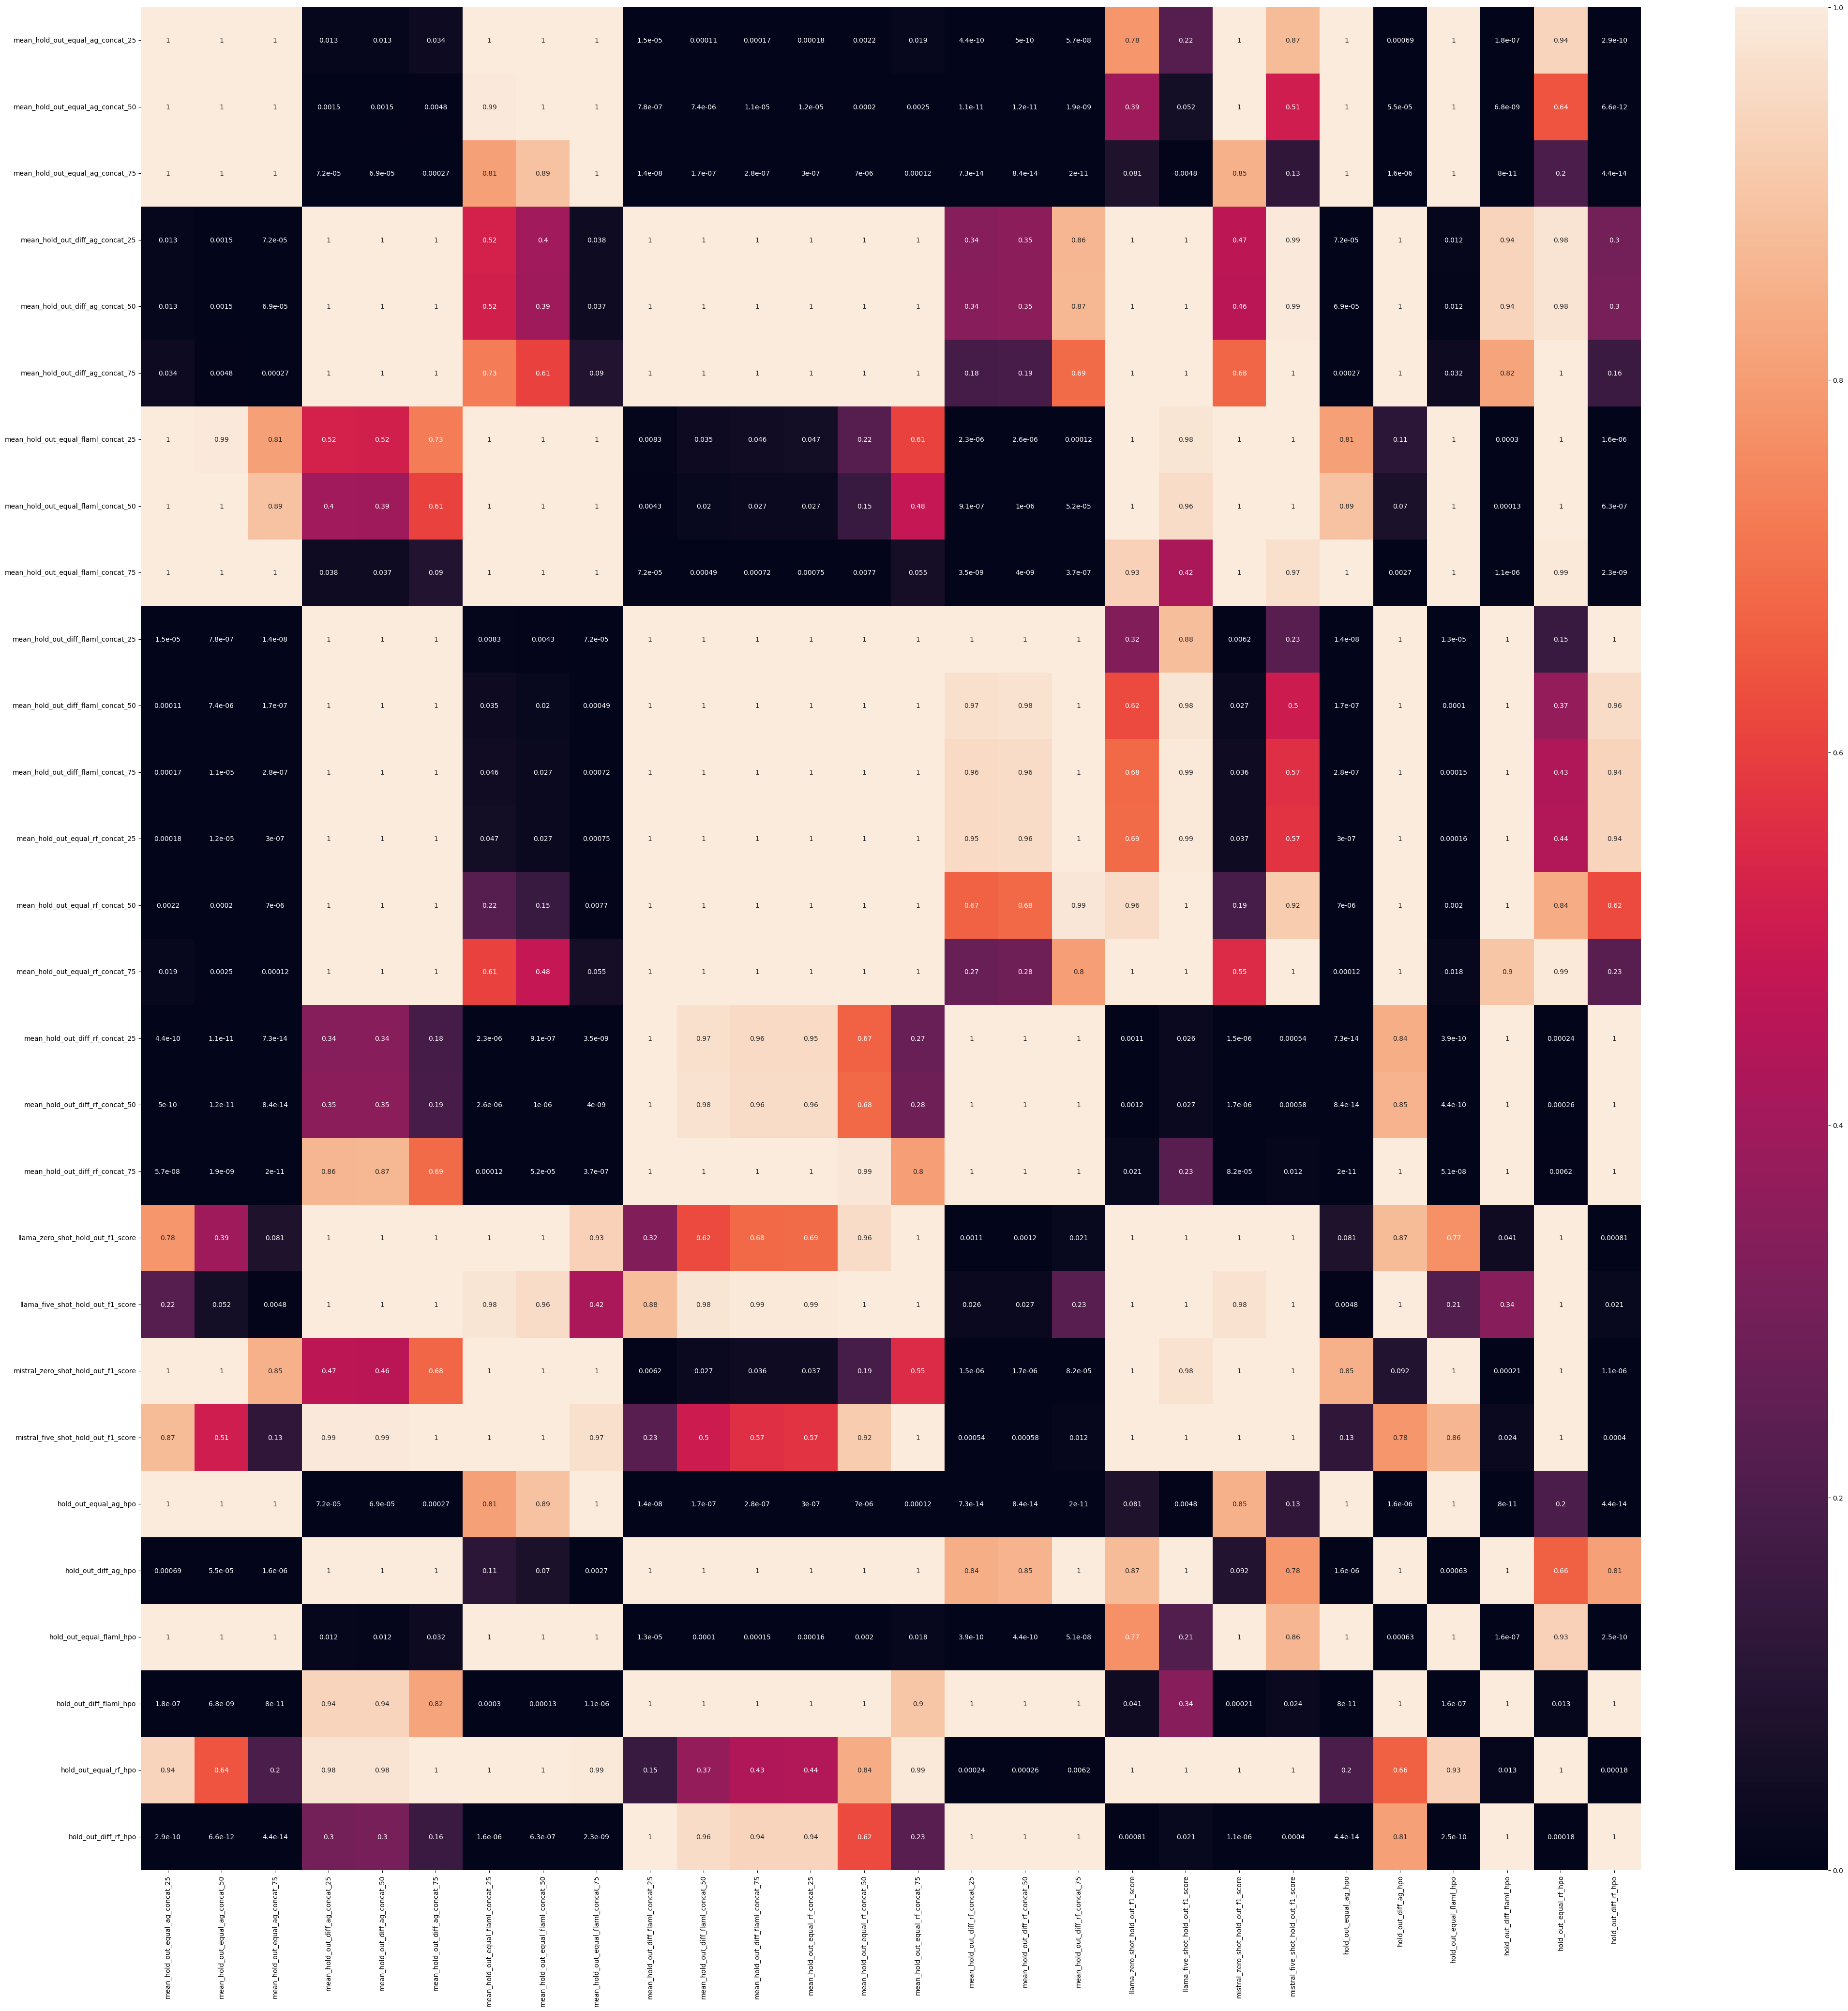

In [79]:
plt.figure(figsize=(50, 50))
sns.heatmap(posthoc_results, annot=True, xticklabels=posthoc_results.columns, yticklabels=posthoc_results.index)
plt.savefig("posthoc_nemenyi_23_datasets.pdf", format="pdf", bbox_inches="tight")

In [80]:
stats_before_mod_df

,predicted_dataset,mean_hold_out_equal_ag_concat_25,mean_hold_out_equal_ag_concat_50,mean_hold_out_equal_ag_concat_75,mean_hold_out_diff_ag_concat_25,mean_hold_out_diff_ag_concat_50,mean_hold_out_diff_ag_concat_75,mean_hold_out_equal_flaml_concat_25,mean_hold_out_equal_flaml_concat_50,mean_hold_out_equal_flaml_concat_75,...,llama_zero_shot_hold_out_f1_score,llama_five_shot_hold_out_f1_score,mistral_zero_shot_hold_out_f1_score,mistral_five_shot_hold_out_f1_score,hold_out_equal_ag_hpo,hold_out_diff_ag_hpo,hold_out_equal_flaml_hpo,hold_out_diff_flaml_hpo,hold_out_equal_rf_hpo,hold_out_diff_rf_hpo
0,ed_01,0.132780,0.302905,0.294606,0.012448,0.020747,0.037344,0.000000,0.029046,0.045643,...,0.381743,0.448133,0.481328,0.543568,0.468880,0.020747,0.439834,0.000000,0.348548,0.000000
1,ed_02,0.667767,0.638624,0.708556,0.107823,0.147415,0.121949,0.553659,0.557678,0.521079,...,0.566905,0.548982,0.602581,0.577312,0.766363,0.190505,0.553599,0.031118,0.379427,0.000000
2,ed_03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.199409,0.174021,0.280096,0.213996,0.479597,NaN,0.381555,NaN,0.294867,NaN
3,ed_04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.126210,0.493725,0.297598,0.192542,0.925421,NaN,0.915740,NaN,0.904984,NaN
4,ed_05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.291667,0.291667,0.400000,0.383333,0.375000,NaN,0.391667,NaN,0.341667,NaN
5,fn_01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.134788,0.109856,0.241138,0.236073,0.267238,NaN,0.236852,NaN,0.200623,NaN
6,fn_02,0.459722,0.455556,0.529167,0.350694,0.362847,0.362847,0.481944,0.445833,0.506944,...,0.687500,0.687500,0.569444,0.569444,0.500000,0.344444,0.541667,0.352778,0.451389,0.304167
7,fn_03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.181792,0.176066,0.219582,0.243630,0.267678,NaN,0.225308,NaN,0.198683,NaN
8,fn_04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.113368,0.098296,0.250328,0.279161,0.559633,NaN,0.563565,NaN,0.564875,NaN
9,fn_05,0.519545,0.441110,0.454583,NaN,NaN,NaN,0.451215,0.414779,0.477955,...,0.377271,0.386405,0.373239,0.396969,0.538171,0.388345,0.470249,0.387069,0.333946,0.377322


In [81]:
stats_before_mod_df.dropna().describe()

,mean_hold_out_equal_ag_concat_25,mean_hold_out_equal_ag_concat_50,mean_hold_out_equal_ag_concat_75,mean_hold_out_diff_ag_concat_25,mean_hold_out_diff_ag_concat_50,mean_hold_out_diff_ag_concat_75,mean_hold_out_equal_flaml_concat_25,mean_hold_out_equal_flaml_concat_50,mean_hold_out_equal_flaml_concat_75,mean_hold_out_diff_flaml_concat_25,...,llama_zero_shot_hold_out_f1_score,llama_five_shot_hold_out_f1_score,mistral_zero_shot_hold_out_f1_score,mistral_five_shot_hold_out_f1_score,hold_out_equal_ag_hpo,hold_out_diff_ag_hpo,hold_out_equal_flaml_hpo,hold_out_diff_flaml_hpo,hold_out_equal_rf_hpo,hold_out_diff_rf_hpo
count,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,...,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000
mean,0.664140,0.678201,0.692772,0.525165,0.520625,0.529029,0.634008,0.641453,0.651089,0.491736,...,0.578638,0.558252,0.624720,0.568868,0.707591,0.494259,0.686117,0.457700,0.614550,0.414448
std,0.187676,0.169041,0.160162,0.202419,0.197202,0.196646,0.201098,0.199717,0.194975,0.205572,...,0.253469,0.200664,0.260387,0.274470,0.152791,0.186713,0.157822,0.200556,0.176242,0.213346
min,0.132780,0.302905,0.294606,0.012448,0.020747,0.037344,0.000000,0.029046,0.045643,0.004149,...,0.141791,0.142244,0.129353,0.078628,0.459916,0.020747,0.439834,0.000000,0.334867,0.000000
25%,0.553195,0.568432,0.585817,0.450904,0.390295,0.445736,0.518575,0.526582,0.521666,0.419536,...,0.381743,0.448133,0.399480,0.338501,0.583712,0.366925,0.547459,0.366255,0.479628,0.314384
50%,0.667767,0.660358,0.681667,0.554108,0.561004,0.561945,0.645724,0.645833,0.657626,0.547887,...,0.566905,0.548982,0.602581,0.577312,0.700000,0.525567,0.666341,0.487718,0.621162,0.403524
75%,0.803841,0.828532,0.822359,0.655466,0.645778,0.658683,0.772828,0.796004,0.792847,0.619248,...,0.837034,0.726745,0.854983,0.831793,0.835391,0.595963,0.797581,0.562058,0.751029,0.520599
max,0.943457,0.947047,0.950759,0.850942,0.839975,0.841391,0.936774,0.941438,0.943053,0.824771,...,0.955095,0.905203,0.957584,0.929178,0.956007,0.853393,0.948304,0.862682,0.951535,0.887722


In [82]:
stats_before_mod_df.describe()

,mean_hold_out_equal_ag_concat_25,mean_hold_out_equal_ag_concat_50,mean_hold_out_equal_ag_concat_75,mean_hold_out_diff_ag_concat_25,mean_hold_out_diff_ag_concat_50,mean_hold_out_diff_ag_concat_75,mean_hold_out_equal_flaml_concat_25,mean_hold_out_equal_flaml_concat_50,mean_hold_out_equal_flaml_concat_75,mean_hold_out_diff_flaml_concat_25,...,llama_zero_shot_hold_out_f1_score,llama_five_shot_hold_out_f1_score,mistral_zero_shot_hold_out_f1_score,mistral_five_shot_hold_out_f1_score,hold_out_equal_ag_hpo,hold_out_diff_ag_hpo,hold_out_equal_flaml_hpo,hold_out_diff_flaml_hpo,hold_out_equal_rf_hpo,hold_out_diff_rf_hpo
count,35.000000,35.000000,35.000000,25.000000,25.000000,25.000000,35.000000,35.000000,35.000000,25.000000,...,48.000000,48.000000,48.000000,48.000000,49.000000,35.000000,49.000000,35.000000,49.000000,35.000000
mean,0.633017,0.652287,0.671255,0.525165,0.520625,0.529029,0.603661,0.617315,0.639313,0.491736,...,0.487738,0.477694,0.548745,0.525211,0.682097,0.480669,0.651403,0.452895,0.580845,0.412183
std,0.191680,0.179052,0.168134,0.202419,0.197202,0.196646,0.207143,0.200644,0.199056,0.205572,...,0.264357,0.232076,0.243079,0.245094,0.189723,0.177722,0.192627,0.191450,0.201611,0.208909
min,0.132780,0.302905,0.294606,0.012448,0.020747,0.037344,0.000000,0.029046,0.045643,0.004149,...,0.047493,0.091029,0.121450,0.078628,0.251714,0.020747,0.225308,0.000000,0.198683,0.000000
25%,0.488301,0.491901,0.516668,0.450904,0.390295,0.445736,0.466579,0.453000,0.496108,0.419536,...,0.281352,0.315919,0.370086,0.334955,0.538171,0.366796,0.538874,0.359516,0.442095,0.317192
50%,0.653509,0.647759,0.654959,0.554108,0.561004,0.561945,0.600877,0.605263,0.627385,0.547887,...,0.456067,0.483297,0.554755,0.550451,0.700000,0.467868,0.666341,0.437183,0.564875,0.394640
75%,0.773981,0.812106,0.823203,0.655466,0.645778,0.658683,0.760556,0.774619,0.796083,0.619248,...,0.661875,0.686106,0.766922,0.710410,0.835391,0.592742,0.797581,0.557344,0.726891,0.508509
max,0.943457,0.947047,0.950759,0.850942,0.839975,0.841391,0.936774,0.941438,0.943053,0.824771,...,0.955095,0.905203,0.957584,0.929178,0.960526,0.853393,0.948304,0.883704,0.951535,0.906004


In [83]:
stats_before_mod_df.describe()

,mean_hold_out_equal_ag_concat_25,mean_hold_out_equal_ag_concat_50,mean_hold_out_equal_ag_concat_75,mean_hold_out_diff_ag_concat_25,mean_hold_out_diff_ag_concat_50,mean_hold_out_diff_ag_concat_75,mean_hold_out_equal_flaml_concat_25,mean_hold_out_equal_flaml_concat_50,mean_hold_out_equal_flaml_concat_75,mean_hold_out_diff_flaml_concat_25,...,llama_zero_shot_hold_out_f1_score,llama_five_shot_hold_out_f1_score,mistral_zero_shot_hold_out_f1_score,mistral_five_shot_hold_out_f1_score,hold_out_equal_ag_hpo,hold_out_diff_ag_hpo,hold_out_equal_flaml_hpo,hold_out_diff_flaml_hpo,hold_out_equal_rf_hpo,hold_out_diff_rf_hpo
count,35.000000,35.000000,35.000000,25.000000,25.000000,25.000000,35.000000,35.000000,35.000000,25.000000,...,48.000000,48.000000,48.000000,48.000000,49.000000,35.000000,49.000000,35.000000,49.000000,35.000000
mean,0.633017,0.652287,0.671255,0.525165,0.520625,0.529029,0.603661,0.617315,0.639313,0.491736,...,0.487738,0.477694,0.548745,0.525211,0.682097,0.480669,0.651403,0.452895,0.580845,0.412183
std,0.191680,0.179052,0.168134,0.202419,0.197202,0.196646,0.207143,0.200644,0.199056,0.205572,...,0.264357,0.232076,0.243079,0.245094,0.189723,0.177722,0.192627,0.191450,0.201611,0.208909
min,0.132780,0.302905,0.294606,0.012448,0.020747,0.037344,0.000000,0.029046,0.045643,0.004149,...,0.047493,0.091029,0.121450,0.078628,0.251714,0.020747,0.225308,0.000000,0.198683,0.000000
25%,0.488301,0.491901,0.516668,0.450904,0.390295,0.445736,0.466579,0.453000,0.496108,0.419536,...,0.281352,0.315919,0.370086,0.334955,0.538171,0.366796,0.538874,0.359516,0.442095,0.317192
50%,0.653509,0.647759,0.654959,0.554108,0.561004,0.561945,0.600877,0.605263,0.627385,0.547887,...,0.456067,0.483297,0.554755,0.550451,0.700000,0.467868,0.666341,0.437183,0.564875,0.394640
75%,0.773981,0.812106,0.823203,0.655466,0.645778,0.658683,0.760556,0.774619,0.796083,0.619248,...,0.661875,0.686106,0.766922,0.710410,0.835391,0.592742,0.797581,0.557344,0.726891,0.508509
max,0.943457,0.947047,0.950759,0.850942,0.839975,0.841391,0.936774,0.941438,0.943053,0.824771,...,0.955095,0.905203,0.957584,0.929178,0.960526,0.853393,0.948304,0.883704,0.951535,0.906004


In [84]:
stats_before_mod_df[stats_before_mod_df.columns[-20:]].describe()

,mean_hold_out_equal_flaml_concat_75,mean_hold_out_diff_flaml_concat_25,mean_hold_out_diff_flaml_concat_50,mean_hold_out_diff_flaml_concat_75,mean_hold_out_equal_rf_concat_25,mean_hold_out_equal_rf_concat_50,mean_hold_out_equal_rf_concat_75,mean_hold_out_diff_rf_concat_25,mean_hold_out_diff_rf_concat_50,mean_hold_out_diff_rf_concat_75,llama_zero_shot_hold_out_f1_score,llama_five_shot_hold_out_f1_score,mistral_zero_shot_hold_out_f1_score,mistral_five_shot_hold_out_f1_score,hold_out_equal_ag_hpo,hold_out_diff_ag_hpo,hold_out_equal_flaml_hpo,hold_out_diff_flaml_hpo,hold_out_equal_rf_hpo,hold_out_diff_rf_hpo
count,35.000000,25.000000,25.000000,25.000000,35.000000,35.000000,35.000000,25.000000,25.000000,25.000000,48.000000,48.000000,48.000000,48.000000,49.000000,35.000000,49.000000,35.000000,49.000000,35.000000
mean,0.639313,0.491736,0.494555,0.495049,0.480162,0.509328,0.518267,0.421679,0.431683,0.446468,0.487738,0.477694,0.548745,0.525211,0.682097,0.480669,0.651403,0.452895,0.580845,0.412183
std,0.199056,0.205572,0.206067,0.206462,0.213171,0.199646,0.200431,0.217959,0.206628,0.209038,0.264357,0.232076,0.243079,0.245094,0.189723,0.177722,0.192627,0.191450,0.201611,0.208909
min,0.045643,0.004149,0.018017,0.014674,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.047493,0.091029,0.121450,0.078628,0.251714,0.020747,0.225308,0.000000,0.198683,0.000000
25%,0.496108,0.419536,0.416021,0.401809,0.333640,0.371000,0.390507,0.294888,0.304910,0.331276,0.281352,0.315919,0.370086,0.334955,0.538171,0.366796,0.538874,0.359516,0.442095,0.317192
50%,0.627385,0.547887,0.541718,0.540649,0.446033,0.517544,0.517544,0.454685,0.438739,0.461898,0.456067,0.483297,0.554755,0.550451,0.700000,0.467868,0.666341,0.437183,0.564875,0.394640
75%,0.796083,0.619248,0.623919,0.619333,0.582037,0.611916,0.642066,0.525248,0.524639,0.521593,0.661875,0.686106,0.766922,0.710410,0.835391,0.592742,0.797581,0.557344,0.726891,0.508509
max,0.943053,0.824771,0.847232,0.853632,0.949919,0.951535,0.951535,0.867097,0.873332,0.907054,0.955095,0.905203,0.957584,0.929178,0.960526,0.853393,0.948304,0.883704,0.951535,0.906004


In [85]:
stats_df.columns

Index(['mean_hold_out_equal_ag_concat_25', 'mean_hold_out_equal_ag_concat_50',
       'mean_hold_out_equal_ag_concat_75', 'mean_hold_out_diff_ag_concat_25',
       'mean_hold_out_diff_ag_concat_50', 'mean_hold_out_diff_ag_concat_75',
       'mean_hold_out_equal_flaml_concat_25',
       'mean_hold_out_equal_flaml_concat_50',
       'mean_hold_out_equal_flaml_concat_75',
       'mean_hold_out_diff_flaml_concat_25',
       'mean_hold_out_diff_flaml_concat_50',
       'mean_hold_out_diff_flaml_concat_75',
       'mean_hold_out_equal_rf_concat_25', 'mean_hold_out_equal_rf_concat_50',
       'mean_hold_out_equal_rf_concat_75', 'mean_hold_out_diff_rf_concat_25',
       'mean_hold_out_diff_rf_concat_50', 'mean_hold_out_diff_rf_concat_75',
       'llama_zero_shot_hold_out_f1_score',
       'llama_five_shot_hold_out_f1_score',
       'mistral_zero_shot_hold_out_f1_score',
       'mistral_five_shot_hold_out_f1_score', 'hold_out_equal_ag_hpo',
       'hold_out_diff_ag_hpo', 'hold_out_equal_flaml_h

In [86]:
list_ = list(stats_df.columns)
print(list_)
only_llm_hpo_list = [item for item in list_ if (("hpo" in item) and ("equal" in item)) or ("shot" in item)]
only_llm_hpo_list

['mean_hold_out_equal_ag_concat_25', 'mean_hold_out_equal_ag_concat_50', 'mean_hold_out_equal_ag_concat_75', 'mean_hold_out_diff_ag_concat_25', 'mean_hold_out_diff_ag_concat_50', 'mean_hold_out_diff_ag_concat_75', 'mean_hold_out_equal_flaml_concat_25', 'mean_hold_out_equal_flaml_concat_50', 'mean_hold_out_equal_flaml_concat_75', 'mean_hold_out_diff_flaml_concat_25', 'mean_hold_out_diff_flaml_concat_50', 'mean_hold_out_diff_flaml_concat_75', 'mean_hold_out_equal_rf_concat_25', 'mean_hold_out_equal_rf_concat_50', 'mean_hold_out_equal_rf_concat_75', 'mean_hold_out_diff_rf_concat_25', 'mean_hold_out_diff_rf_concat_50', 'mean_hold_out_diff_rf_concat_75', 'llama_zero_shot_hold_out_f1_score', 'llama_five_shot_hold_out_f1_score', 'mistral_zero_shot_hold_out_f1_score', 'mistral_five_shot_hold_out_f1_score', 'hold_out_equal_ag_hpo', 'hold_out_diff_ag_hpo', 'hold_out_equal_flaml_hpo', 'hold_out_diff_flaml_hpo', 'hold_out_equal_rf_hpo', 'hold_out_diff_rf_hpo']


['llama_zero_shot_hold_out_f1_score',
 'llama_five_shot_hold_out_f1_score',
 'mistral_zero_shot_hold_out_f1_score',
 'mistral_five_shot_hold_out_f1_score',
 'hold_out_equal_ag_hpo',
 'hold_out_equal_flaml_hpo',
 'hold_out_equal_rf_hpo']

In [87]:
final_comparison_llm_df = stats_before_mod_df[only_llm_hpo_list]
final_comparison_llm_df = final_comparison_llm_df.dropna()
final_comparison_llm_df

,llama_zero_shot_hold_out_f1_score,llama_five_shot_hold_out_f1_score,mistral_zero_shot_hold_out_f1_score,mistral_five_shot_hold_out_f1_score,hold_out_equal_ag_hpo,hold_out_equal_flaml_hpo,hold_out_equal_rf_hpo
0,0.381743,0.448133,0.481328,0.543568,0.468880,0.439834,0.348548
1,0.566905,0.548982,0.602581,0.577312,0.766363,0.553599,0.379427
2,0.199409,0.174021,0.280096,0.213996,0.479597,0.381555,0.294867
3,0.126210,0.493725,0.297598,0.192542,0.925421,0.915740,0.904984
4,0.291667,0.291667,0.400000,0.383333,0.375000,0.391667,0.341667
5,0.134788,0.109856,0.241138,0.236073,0.267238,0.236852,0.200623
6,0.687500,0.687500,0.569444,0.569444,0.500000,0.541667,0.451389
7,0.181792,0.176066,0.219582,0.243630,0.267678,0.225308,0.198683
8,0.113368,0.098296,0.250328,0.279161,0.559633,0.563565,0.564875
9,0.377271,0.386405,0.373239,0.396969,0.538171,0.470249,0.333946


In [88]:
len(final_comparison_llm_df)

48

In [89]:
final_comparison_llm_df.describe()

,llama_zero_shot_hold_out_f1_score,llama_five_shot_hold_out_f1_score,mistral_zero_shot_hold_out_f1_score,mistral_five_shot_hold_out_f1_score,hold_out_equal_ag_hpo,hold_out_equal_flaml_hpo,hold_out_equal_rf_hpo
count,48.000000,48.000000,48.000000,48.000000,48.000000,48.000000,48.000000
mean,0.487738,0.477694,0.548745,0.525211,0.678798,0.650421,0.582402
std,0.264357,0.232076,0.243079,0.245094,0.190305,0.194541,0.203447
min,0.047493,0.091029,0.121450,0.078628,0.251714,0.225308,0.198683
25%,0.281352,0.315919,0.370086,0.334955,0.537861,0.529683,0.426919
50%,0.456067,0.483297,0.554755,0.550451,0.697025,0.648171,0.571142
75%,0.661875,0.686106,0.766922,0.710410,0.835034,0.802731,0.732925
max,0.955095,0.905203,0.957584,0.929178,0.960526,0.948304,0.951535


In [90]:
stats.friedmanchisquare(*[final_comparison_llm_df[selected_column].to_list() for selected_column in final_comparison_llm_df.columns])

FriedmanchisquareResult(statistic=np.float64(74.8686868686869), pvalue=np.float64(4.0848305861696414e-14))

In [91]:
posthoc_results_llm = sp.posthoc_nemenyi_friedman(final_comparison_llm_df)
posthoc_results_llm

,llama_zero_shot_hold_out_f1_score,llama_five_shot_hold_out_f1_score,mistral_zero_shot_hold_out_f1_score,mistral_five_shot_hold_out_f1_score,hold_out_equal_ag_hpo,hold_out_equal_flaml_hpo,hold_out_equal_rf_hpo
llama_zero_shot_hold_out_f1_score,1.000000e+00,9.888953e-01,0.225510,0.379775,3.222639e-09,0.000181,0.883301
llama_five_shot_hold_out_f1_score,9.888953e-01,1.000000e+00,0.032370,0.073322,1.722633e-11,0.000004,0.424639
mistral_zero_shot_hold_out_f1_score,2.255102e-01,3.236976e-02,1.000000,0.999958,9.527716e-04,0.351062,0.925234
mistral_five_shot_hold_out_f1_score,3.797752e-01,7.332211e-02,0.999958,1.000000,2.784375e-04,0.204401,0.982257
hold_out_equal_ag_hpo,3.222639e-09,1.722633e-11,0.000953,0.000278,1.000000e+00,0.440003,0.000005
hold_out_equal_flaml_hpo,1.813127e-04,4.212015e-06,0.351062,0.204401,4.400033e-01,1.000000,0.022343
hold_out_equal_rf_hpo,8.833015e-01,4.246385e-01,0.925234,0.982257,4.779152e-06,0.022343,1.000000


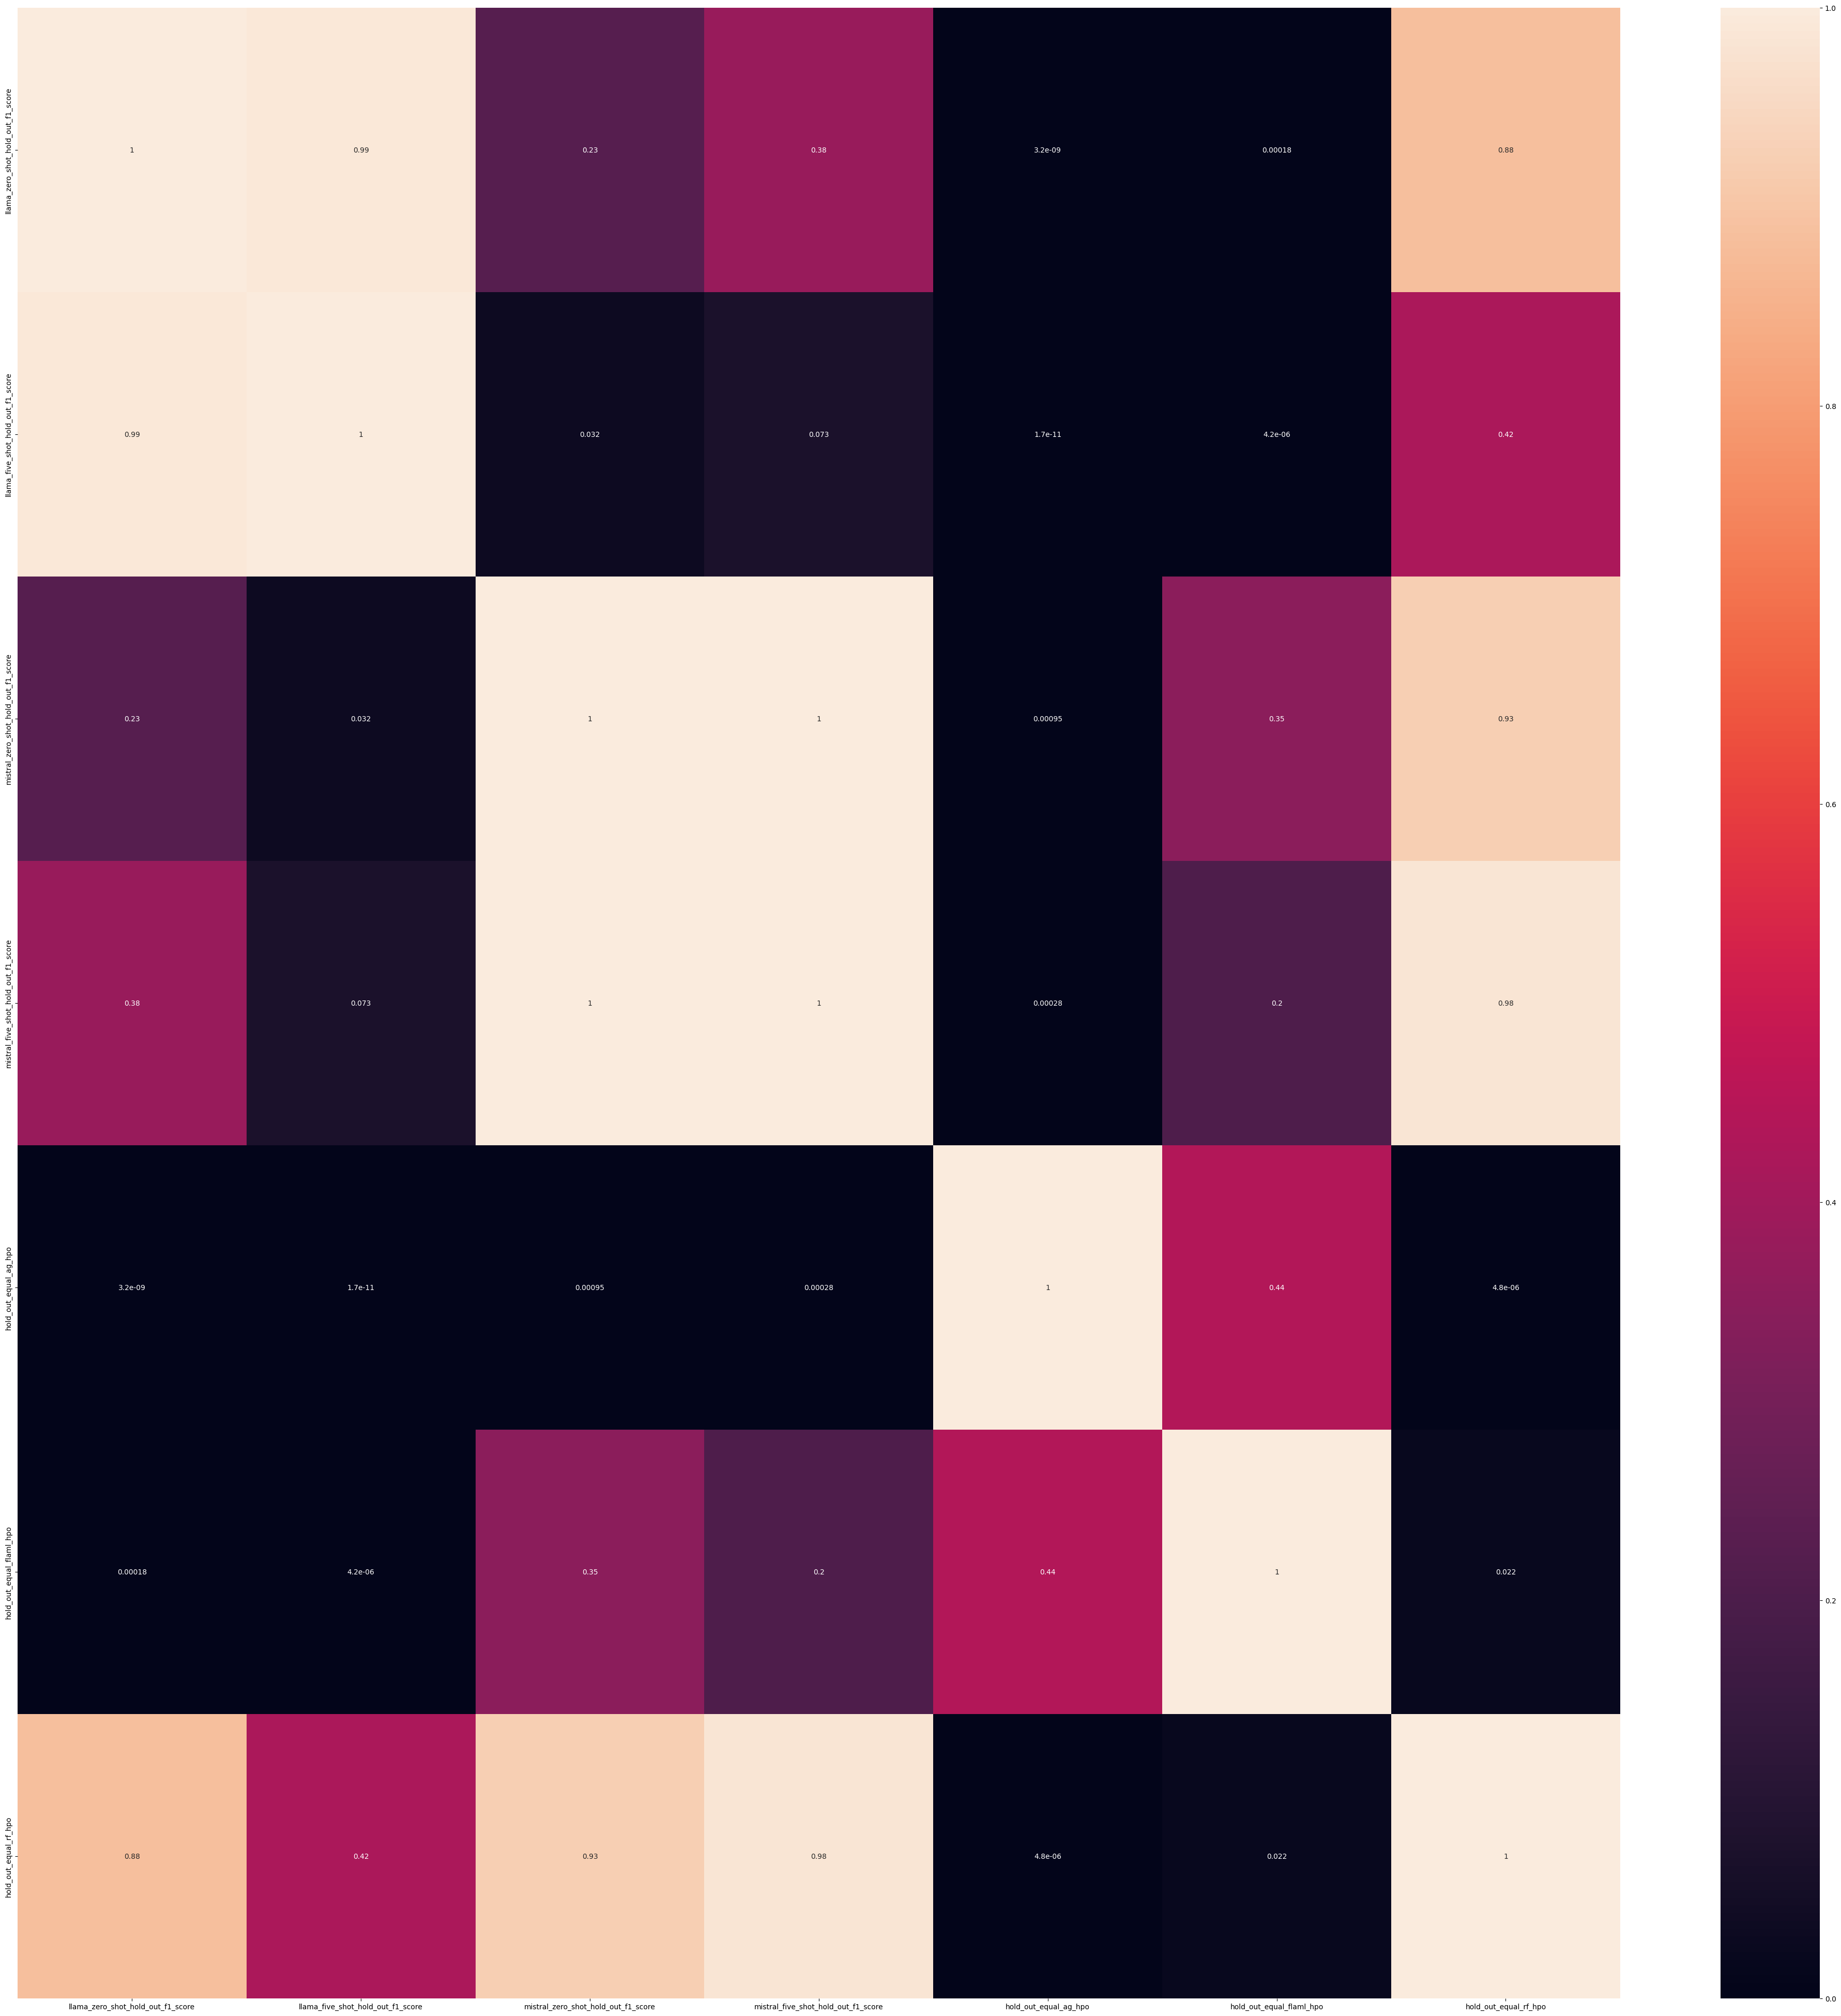

In [92]:
plt.figure(figsize=(50, 50))
sns.heatmap(posthoc_results_llm, annot=True, xticklabels=posthoc_results_llm.columns, yticklabels=posthoc_results_llm.index)
plt.savefig("posthoc_nemenyi_48_datasets.pdf", format="pdf", bbox_inches="tight")

In [93]:
# import matplotlib.pyplot as plt
# import seaborn as sns

# fig, ax = plt.subplots(figsize=(50, 50))

# # Plot heatmap
# sns.heatmap(posthoc_results, annot=True,
#             xticklabels=posthoc_results.columns,
#             yticklabels=posthoc_results.index,
#             ax=ax, cbar=False)

# # Set axis labels
# ax.set_xlabel("Predicted Dataset", fontsize=50)
# ax.set_ylabel("Actual Dataset", fontsize=50)

# # Set tick label sizes and positions (bottom + top for x, left + right for y)
# ax.tick_params(axis='x', labelsize=50, labelbottom=True, labeltop=True)
# ax.tick_params(axis='y', labelsize=50, labelleft=True, labelright=True)

# # Rotate labels if needed
# plt.xticks(rotation=90)
# plt.yticks(rotation=0)

# plt.tight_layout()
# plt.show()


In [94]:
min_max_diff_df
desired_list = [item for item in min_max_diff_df.columns if ("min_max" in item) or ("zero_five" in item) or ("predicted_dataset" in item)]
min_max_diff_df = min_max_diff_df[desired_list]
min_max_diff_df

,min_max_equal_ag_concat_25,min_max_equal_ag_concat_50,min_max_equal_ag_concat_75,min_max_diff_ag_concat_25,min_max_diff_ag_concat_50,min_max_diff_ag_concat_75,min_max_equal_flaml_concat_25,min_max_equal_flaml_concat_50,min_max_equal_flaml_concat_75,min_max_diff_flaml_concat_25,...,min_max_diff_flaml_concat_75,min_max_equal_rf_concat_25,min_max_equal_rf_concat_50,min_max_equal_rf_concat_75,min_max_diff_rf_concat_25,min_max_diff_rf_concat_50,min_max_diff_rf_concat_75,llama_zero_five_diff_shot_hold_out_f1_score,mistral_zero_five_diff_shot_hold_out_f1_score,predicted_dataset
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.066390,0.062241,ed_01
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.017923,-0.025269,ed_02
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.025388,-0.066100,ed_03
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.367515,-0.105056,ed_04
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,-0.016667,ed_05
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.024932,-0.005064,fn_01
6,0.118056,0.027778,0.138889,0.402778,0.368056,0.395833,0.159722,0.111111,0.083333,0.236111,...,0.256944,0.520833,0.520833,0.520833,0.520833,0.520833,0.000000,0.000000,0.000000,fn_02
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.005726,0.024048,fn_03
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.015072,0.028834,fn_04
9,0.000000,0.000000,0.000000,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,...,NaN,0.000000,0.000000,0.000000,NaN,NaN,NaN,0.009135,0.023729,fn_05


In [95]:
described_min_max_diff_df = min_max_diff_df.describe()
described_min_max_diff_df

,min_max_equal_ag_concat_25,min_max_equal_ag_concat_50,min_max_equal_ag_concat_75,min_max_diff_ag_concat_25,min_max_diff_ag_concat_50,min_max_diff_ag_concat_75,min_max_equal_flaml_concat_25,min_max_equal_flaml_concat_50,min_max_equal_flaml_concat_75,min_max_diff_flaml_concat_25,min_max_diff_flaml_concat_50,min_max_diff_flaml_concat_75,min_max_equal_rf_concat_25,min_max_equal_rf_concat_50,min_max_equal_rf_concat_75,min_max_diff_rf_concat_25,min_max_diff_rf_concat_50,min_max_diff_rf_concat_75,llama_zero_five_diff_shot_hold_out_f1_score,mistral_zero_five_diff_shot_hold_out_f1_score
count,35.000000,35.000000,35.000000,25.000000,25.000000,25.000000,35.000000,35.000000,35.000000,25.000000,25.000000,25.000000,35.000000,35.000000,35.000000,25.000000,25.000000,25.000000,48.000000,48.000000
mean,0.051382,0.042255,0.039305,0.250509,0.280100,0.235580,0.065363,0.055948,0.054384,0.316170,0.292973,0.284602,0.169469,0.131334,0.115568,0.382996,0.359694,0.299500,-0.010043,-0.023534
std,0.081000,0.076394,0.055465,0.185513,0.188778,0.162323,0.115843,0.109528,0.106805,0.251972,0.236330,0.223751,0.246435,0.207783,0.186047,0.285021,0.256276,0.266618,0.141152,0.113860
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.411475,-0.348508
25%,0.000000,0.000000,0.000000,0.091916,0.147029,0.108108,0.000000,0.000000,0.000000,0.107421,0.111744,0.122154,0.000000,0.000000,0.000000,0.139183,0.135135,0.040541,-0.055450,-0.031807
50%,0.033752,0.027489,0.029440,0.220872,0.254959,0.205147,0.028651,0.024458,0.035025,0.236111,0.230169,0.236598,0.040541,0.000000,0.002115,0.339528,0.339528,0.223089,0.000000,-0.001029
75%,0.066128,0.053544,0.052225,0.390423,0.447257,0.390947,0.076666,0.073960,0.065250,0.487562,0.480100,0.477612,0.199029,0.178473,0.166233,0.664919,0.567044,0.464135,0.046061,0.047230
max,0.434109,0.434109,0.279070,0.619819,0.605179,0.526394,0.622739,0.635659,0.625323,0.756259,0.720379,0.759093,0.816537,0.816537,0.816537,0.840107,0.750708,0.750708,0.367515,0.106667


# Frequency of Hallucination, missed classes, and better than the mode

In [96]:
# concat case:

# autogluon - separate for each percentage after
automl_concat_ag_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_ag.csv", sep=";")

# automl_concat_ag_df["are_concat_pred_equal"] = automl_concat_ag_df.apply(lambda row: row["concatenated_dataset"] == row["predicted_dataset"], axis=1)

# equal_concat_ag_df = automl_concat_ag_df[automl_concat_ag_df["are_concat_pred_equal"]]
# diff_concat_ag_df = automl_concat_ag_df[~(automl_concat_ag_df["are_concat_pred_equal"])]

adapt_mask = automl_concat_ag_df["concatenated_dataset"] == automl_concat_ag_df["predicted_dataset"]
aug_mask = automl_concat_ag_df["trained_dataset"] == automl_concat_ag_df["predicted_dataset"]

equal_concat_ag_df = automl_concat_ag_df.loc[adapt_mask & (~aug_mask)]
diff_concat_ag_df = automl_concat_ag_df.loc[(~adapt_mask) & (~aug_mask)]

equal_concat_ag_df_25 = equal_concat_ag_df[equal_concat_ag_df["percentage"]==25]
equal_concat_ag_df_25["has_missed_labels"] = equal_concat_ag_df_25["missing_in_pred"].apply(lambda x: has_missed_labels(x))
equal_concat_ag_df_25["did_hallucinate"] = equal_concat_ag_df_25["extra_in_pred"].apply(lambda x: did_hallucinate(x))
equal_concat_ag_df_25["is_better_than_dummy"] = equal_concat_ag_df_25.apply(lambda row: is_better_than_dummy(row), axis=1)

equal_concat_ag_df_50 = equal_concat_ag_df[equal_concat_ag_df["percentage"]==50]
equal_concat_ag_df_50["has_missed_labels"] = equal_concat_ag_df_50["missing_in_pred"].apply(lambda x: has_missed_labels(x))
equal_concat_ag_df_50["did_hallucinate"] = equal_concat_ag_df_50["extra_in_pred"].apply(lambda x: did_hallucinate(x))
equal_concat_ag_df_50["is_better_than_dummy"] = equal_concat_ag_df_50.apply(lambda row: is_better_than_dummy(row), axis=1)

equal_concat_ag_df_75 = equal_concat_ag_df[equal_concat_ag_df["percentage"]==75]
equal_concat_ag_df_75["has_missed_labels"] = equal_concat_ag_df_75["missing_in_pred"].apply(lambda x: has_missed_labels(x))
equal_concat_ag_df_75["did_hallucinate"] = equal_concat_ag_df_75["extra_in_pred"].apply(lambda x: did_hallucinate(x))
equal_concat_ag_df_75["is_better_than_dummy"] = equal_concat_ag_df_75.apply(lambda row: is_better_than_dummy(row), axis=1)

diff_concat_ag_df_25 = diff_concat_ag_df[diff_concat_ag_df["percentage"]==25]
diff_concat_ag_df_25["has_missed_labels"] = diff_concat_ag_df_25["missing_in_pred"].apply(lambda x: has_missed_labels(x))
diff_concat_ag_df_25["did_hallucinate"] = diff_concat_ag_df_25["extra_in_pred"].apply(lambda x: did_hallucinate(x))
diff_concat_ag_df_25["is_better_than_dummy"] = diff_concat_ag_df_25.apply(lambda row: is_better_than_dummy(row), axis=1)

diff_concat_ag_df_50 = diff_concat_ag_df[diff_concat_ag_df["percentage"]==50]
diff_concat_ag_df_50["has_missed_labels"] = diff_concat_ag_df_50["missing_in_pred"].apply(lambda x: has_missed_labels(x))
diff_concat_ag_df_50["did_hallucinate"] = diff_concat_ag_df_50["extra_in_pred"].apply(lambda x: did_hallucinate(x))
diff_concat_ag_df_50["is_better_than_dummy"] = diff_concat_ag_df_50.apply(lambda row: is_better_than_dummy(row), axis=1)

diff_concat_ag_df_75 = diff_concat_ag_df[diff_concat_ag_df["percentage"]==75]
diff_concat_ag_df_75["has_missed_labels"] = diff_concat_ag_df_75["missing_in_pred"].apply(lambda x: has_missed_labels(x))
diff_concat_ag_df_75["did_hallucinate"] = diff_concat_ag_df_75["extra_in_pred"].apply(lambda x: did_hallucinate(x))
diff_concat_ag_df_75["is_better_than_dummy"] = diff_concat_ag_df_75.apply(lambda row: is_better_than_dummy(row), axis=1)


# flaml
automl_concat_flaml_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_flaml.csv", sep=";")

# automl_concat_flaml_df["are_concat_pred_equal"] = automl_concat_flaml_df.apply(lambda row: row["concatenated_dataset"] == row["predicted_dataset"], axis=1)

# equal_concat_flaml_df = automl_concat_flaml_df[automl_concat_flaml_df["are_concat_pred_equal"]]
# diff_concat_flaml_df = automl_concat_flaml_df[~(automl_concat_flaml_df["are_concat_pred_equal"])]

adapt_mask = automl_concat_flaml_df["concatenated_dataset"] == automl_concat_flaml_df["predicted_dataset"]
aug_mask = automl_concat_flaml_df["trained_dataset"] == automl_concat_flaml_df["predicted_dataset"]

equal_concat_flaml_df = automl_concat_flaml_df.loc[adapt_mask & (~aug_mask)]
diff_concat_flaml_df = automl_concat_flaml_df.loc[(~adapt_mask) & (~aug_mask)]

equal_concat_flaml_df_25 = equal_concat_flaml_df[equal_concat_flaml_df["percentage"]==25]
equal_concat_flaml_df_25["has_missed_labels"] = equal_concat_flaml_df_25["missing_in_pred"].apply(lambda x: has_missed_labels(x))
equal_concat_flaml_df_25["did_hallucinate"] = equal_concat_flaml_df_25["extra_in_pred"].apply(lambda x: did_hallucinate(x))
equal_concat_flaml_df_25["is_better_than_dummy"] = equal_concat_flaml_df_25.apply(lambda row: is_better_than_dummy(row), axis=1)

equal_concat_flaml_df_50 = equal_concat_flaml_df[equal_concat_flaml_df["percentage"]==50]
equal_concat_flaml_df_50["has_missed_labels"] = equal_concat_flaml_df_50["missing_in_pred"].apply(lambda x: has_missed_labels(x))
equal_concat_flaml_df_50["did_hallucinate"] = equal_concat_flaml_df_50["extra_in_pred"].apply(lambda x: did_hallucinate(x))
equal_concat_flaml_df_50["is_better_than_dummy"] = equal_concat_flaml_df_50.apply(lambda row: is_better_than_dummy(row), axis=1)

equal_concat_flaml_df_75 = equal_concat_flaml_df[equal_concat_flaml_df["percentage"]==75]
equal_concat_flaml_df_75["has_missed_labels"] = equal_concat_flaml_df_75["missing_in_pred"].apply(lambda x: has_missed_labels(x))
equal_concat_flaml_df_75["did_hallucinate"] = equal_concat_flaml_df_75["extra_in_pred"].apply(lambda x: did_hallucinate(x))
equal_concat_flaml_df_75["is_better_than_dummy"] = equal_concat_flaml_df_75.apply(lambda row: is_better_than_dummy(row), axis=1)

diff_concat_flaml_df_25 = diff_concat_flaml_df[diff_concat_flaml_df["percentage"]==25]
diff_concat_flaml_df_25["has_missed_labels"] = diff_concat_flaml_df_25["missing_in_pred"].apply(lambda x: has_missed_labels(x))
diff_concat_flaml_df_25["did_hallucinate"] = diff_concat_flaml_df_25["extra_in_pred"].apply(lambda x: did_hallucinate(x))
diff_concat_flaml_df_25["is_better_than_dummy"] = diff_concat_flaml_df_25.apply(lambda row: is_better_than_dummy(row), axis=1)

diff_concat_flaml_df_50 = diff_concat_flaml_df[diff_concat_flaml_df["percentage"]==50]
diff_concat_flaml_df_50["has_missed_labels"] = diff_concat_flaml_df_50["missing_in_pred"].apply(lambda x: has_missed_labels(x))
diff_concat_flaml_df_50["did_hallucinate"] = diff_concat_flaml_df_50["extra_in_pred"].apply(lambda x: did_hallucinate(x))
diff_concat_flaml_df_50["is_better_than_dummy"] = diff_concat_flaml_df_50.apply(lambda row: is_better_than_dummy(row), axis=1)

diff_concat_flaml_df_75 = diff_concat_flaml_df[diff_concat_flaml_df["percentage"]==75]
diff_concat_flaml_df_75["has_missed_labels"] = diff_concat_flaml_df_75["missing_in_pred"].apply(lambda x: has_missed_labels(x))
diff_concat_flaml_df_75["did_hallucinate"] = diff_concat_flaml_df_75["extra_in_pred"].apply(lambda x: did_hallucinate(x))
diff_concat_flaml_df_75["is_better_than_dummy"] = diff_concat_flaml_df_75.apply(lambda row: is_better_than_dummy(row), axis=1)


# random forest
automl_concat_rf_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_rf.csv", sep=";")

# automl_concat_rf_df["are_concat_pred_equal"] = automl_concat_rf_df.apply(lambda row: row["concatenated_dataset"] == row["predicted_dataset"], axis=1)

# equal_concat_rf_df = automl_concat_rf_df[automl_concat_rf_df["are_concat_pred_equal"]]
# diff_concat_rf_df = automl_concat_rf_df[~(automl_concat_rf_df["are_concat_pred_equal"])]

adapt_mask = automl_concat_rf_df["concatenated_dataset"] == automl_concat_rf_df["predicted_dataset"]
aug_mask = automl_concat_rf_df["trained_dataset"] == automl_concat_rf_df["predicted_dataset"]

equal_concat_rf_df = automl_concat_rf_df.loc[adapt_mask & (~aug_mask)]
diff_concat_rf_df = automl_concat_rf_df.loc[(~adapt_mask) & (~aug_mask)]

equal_concat_rf_df_25 = equal_concat_rf_df[equal_concat_rf_df["percentage"]==25]
equal_concat_rf_df_25["has_missed_labels"] = equal_concat_rf_df_25["missing_in_pred"].apply(lambda x: has_missed_labels(x))
equal_concat_rf_df_25["did_hallucinate"] = equal_concat_rf_df_25["extra_in_pred"].apply(lambda x: did_hallucinate(x))
equal_concat_rf_df_25["is_better_than_dummy"] = equal_concat_rf_df_25.apply(lambda row: is_better_than_dummy(row), axis=1)

equal_concat_rf_df_50 = equal_concat_rf_df[equal_concat_rf_df["percentage"]==50]
equal_concat_rf_df_50["has_missed_labels"] = equal_concat_rf_df_50["missing_in_pred"].apply(lambda x: has_missed_labels(x))
equal_concat_rf_df_50["did_hallucinate"] = equal_concat_rf_df_50["extra_in_pred"].apply(lambda x: did_hallucinate(x))
equal_concat_rf_df_50["is_better_than_dummy"] = equal_concat_rf_df_50.apply(lambda row: is_better_than_dummy(row), axis=1)

equal_concat_rf_df_75 = equal_concat_rf_df[equal_concat_rf_df["percentage"]==75]
equal_concat_rf_df_75["has_missed_labels"] = equal_concat_rf_df_75["missing_in_pred"].apply(lambda x: has_missed_labels(x))
equal_concat_rf_df_75["did_hallucinate"] = equal_concat_rf_df_75["extra_in_pred"].apply(lambda x: did_hallucinate(x))
equal_concat_rf_df_75["is_better_than_dummy"] = equal_concat_rf_df_75.apply(lambda row: is_better_than_dummy(row), axis=1)

diff_concat_rf_df_25 = diff_concat_rf_df[diff_concat_rf_df["percentage"]==25]
diff_concat_rf_df_25["has_missed_labels"] = diff_concat_rf_df_25["missing_in_pred"].apply(lambda x: has_missed_labels(x))
diff_concat_rf_df_25["did_hallucinate"] = diff_concat_rf_df_25["extra_in_pred"].apply(lambda x: did_hallucinate(x))
diff_concat_rf_df_25["is_better_than_dummy"] = diff_concat_rf_df_25.apply(lambda row: is_better_than_dummy(row), axis=1)

diff_concat_rf_df_50 = diff_concat_rf_df[diff_concat_rf_df["percentage"]==50]
diff_concat_rf_df_50["has_missed_labels"] = diff_concat_rf_df_50["missing_in_pred"].apply(lambda x: has_missed_labels(x))
diff_concat_rf_df_50["did_hallucinate"] = diff_concat_rf_df_50["extra_in_pred"].apply(lambda x: did_hallucinate(x))
diff_concat_rf_df_50["is_better_than_dummy"] = diff_concat_rf_df_50.apply(lambda row: is_better_than_dummy(row), axis=1)

diff_concat_rf_df_75 = diff_concat_rf_df[diff_concat_rf_df["percentage"]==75]
diff_concat_rf_df_75["has_missed_labels"] = diff_concat_rf_df_75["missing_in_pred"].apply(lambda x: has_missed_labels(x))
diff_concat_rf_df_75["did_hallucinate"] = diff_concat_rf_df_75["extra_in_pred"].apply(lambda x: did_hallucinate(x))
diff_concat_rf_df_75["is_better_than_dummy"] = diff_concat_rf_df_75.apply(lambda row: is_better_than_dummy(row), axis=1)


# Llama
llama_output_results_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/llama.csv", sep=";")

zero_llama_output_results_df = llama_output_results_df[llama_output_results_df["number_of_examples"]==0]
zero_llama_output_results_df["has_missed_labels"] = zero_llama_output_results_df["missing_in_pred"].apply(lambda x: has_missed_labels(x))
zero_llama_output_results_df["did_hallucinate"] = zero_llama_output_results_df["extra_in_pred"].apply(lambda x: did_hallucinate(x))
zero_llama_output_results_df["is_better_than_dummy"] = zero_llama_output_results_df.apply(lambda row: is_better_than_dummy(row), axis=1)

five_llama_output_results_df = llama_output_results_df[llama_output_results_df["number_of_examples"]==5]
five_llama_output_results_df["has_missed_labels"] = five_llama_output_results_df["missing_in_pred"].apply(lambda x: has_missed_labels(x))
five_llama_output_results_df["did_hallucinate"] = five_llama_output_results_df["extra_in_pred"].apply(lambda x: did_hallucinate(x))
five_llama_output_results_df["is_better_than_dummy"] = five_llama_output_results_df.apply(lambda row: is_better_than_dummy(row), axis=1)


# Mistral
mistral_output_results_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/mistral.csv", sep=";")

zero_mistral_output_results_df = mistral_output_results_df[mistral_output_results_df["number_of_examples"]==0]
zero_mistral_output_results_df["has_missed_labels"] = zero_mistral_output_results_df["missing_in_pred"].apply(lambda x: has_missed_labels(x))
zero_mistral_output_results_df["did_hallucinate"] = zero_mistral_output_results_df["extra_in_pred"].apply(lambda x: did_hallucinate(x))
zero_mistral_output_results_df["is_better_than_dummy"] = zero_mistral_output_results_df.apply(lambda row: is_better_than_dummy(row), axis=1)

five_mistral_output_results_df = mistral_output_results_df[mistral_output_results_df["number_of_examples"]==5]
five_mistral_output_results_df["has_missed_labels"] = five_mistral_output_results_df["missing_in_pred"].apply(lambda x: has_missed_labels(x))
five_mistral_output_results_df["did_hallucinate"] = five_mistral_output_results_df["extra_in_pred"].apply(lambda x: did_hallucinate(x))
five_mistral_output_results_df["is_better_than_dummy"] = five_mistral_output_results_df.apply(lambda row: is_better_than_dummy(row), axis=1)


# HPO
automl_hpo_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/hpo_all_systems.csv", sep=";")
automl_hpo_df["are_trained_pred_equal"] = automl_hpo_df.apply(lambda row: row["trained_dataset"] == row["predicted_dataset"], axis=1)


automl_hpo_ag_df = automl_hpo_df[automl_hpo_df["automl_system"]=="AutoGluon"]

equal_hpo_ag_df = automl_hpo_ag_df[automl_hpo_ag_df["are_trained_pred_equal"]]
equal_hpo_ag_df["has_missed_labels"] = equal_hpo_ag_df["missing_in_pred"].apply(lambda x: has_missed_labels(x))
equal_hpo_ag_df["did_hallucinate"] = equal_hpo_ag_df["extra_in_pred"].apply(lambda x: did_hallucinate(x))
equal_hpo_ag_df["is_better_than_dummy"] = equal_hpo_ag_df.apply(lambda row: is_better_than_dummy(row), axis=1)

diff_hpo_ag_df = automl_hpo_ag_df[~(automl_hpo_ag_df["are_trained_pred_equal"])]
diff_hpo_ag_df["has_missed_labels"] = diff_hpo_ag_df["missing_in_pred"].apply(lambda x: has_missed_labels(x))
diff_hpo_ag_df["did_hallucinate"] = diff_hpo_ag_df["extra_in_pred"].apply(lambda x: did_hallucinate(x))
diff_hpo_ag_df["is_better_than_dummy"] = diff_hpo_ag_df.apply(lambda row: is_better_than_dummy(row), axis=1)


# flaml

automl_hpo_flaml_df = automl_hpo_df[automl_hpo_df["automl_system"]=="FLAML"]

equal_hpo_flaml_df = automl_hpo_flaml_df[automl_hpo_flaml_df["are_trained_pred_equal"]]
equal_hpo_flaml_df["has_missed_labels"] = equal_hpo_flaml_df["missing_in_pred"].apply(lambda x: has_missed_labels(x))
equal_hpo_flaml_df["did_hallucinate"] = equal_hpo_flaml_df["extra_in_pred"].apply(lambda x: did_hallucinate(x))
equal_hpo_flaml_df["is_better_than_dummy"] = equal_hpo_flaml_df.apply(lambda row: is_better_than_dummy(row), axis=1)

diff_hpo_flaml_df = automl_hpo_flaml_df[~(automl_hpo_flaml_df["are_trained_pred_equal"])]
diff_hpo_flaml_df["has_missed_labels"] = diff_hpo_flaml_df["missing_in_pred"].apply(lambda x: has_missed_labels(x))
diff_hpo_flaml_df["did_hallucinate"] = diff_hpo_flaml_df["extra_in_pred"].apply(lambda x: did_hallucinate(x))
diff_hpo_flaml_df["is_better_than_dummy"] = diff_hpo_flaml_df.apply(lambda row: is_better_than_dummy(row), axis=1)


# random forest
automl_hpo_rf_df = automl_hpo_df[automl_hpo_df["automl_system"]=="Random Forest with Random Search"]

equal_hpo_rf_df = automl_hpo_rf_df[automl_hpo_rf_df["are_trained_pred_equal"]]
equal_hpo_rf_df["has_missed_labels"] = equal_hpo_rf_df["missing_in_pred"].apply(lambda x: has_missed_labels(x))
equal_hpo_rf_df["did_hallucinate"] = equal_hpo_rf_df["extra_in_pred"].apply(lambda x: did_hallucinate(x))
equal_hpo_rf_df["is_better_than_dummy"] = equal_hpo_rf_df.apply(lambda row: is_better_than_dummy(row), axis=1)

diff_hpo_rf_df = automl_hpo_rf_df[~(automl_hpo_rf_df["are_trained_pred_equal"])]
diff_hpo_rf_df["has_missed_labels"] = diff_hpo_rf_df["missing_in_pred"].apply(lambda x: has_missed_labels(x))
diff_hpo_rf_df["did_hallucinate"] = diff_hpo_rf_df["extra_in_pred"].apply(lambda x: did_hallucinate(x))
diff_hpo_rf_df["is_better_than_dummy"] = diff_hpo_rf_df.apply(lambda row: is_better_than_dummy(row), axis=1)

/tmp/ipython-input-440462054.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  equal_concat_ag_df_25["has_missed_labels"] = equal_concat_ag_df_25["missing_in_pred"].apply(lambda x: has_missed_labels(x))
/tmp/ipython-input-440462054.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  equal_concat_ag_df_25["did_hallucinate"] = equal_concat_ag_df_25["extra_in_pred"].apply(lambda x: did_hallucinate(x))
/tmp/ipython-input-440462054.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a sl

In [97]:
# I need you to use the freq output of each one and divide by count. After this, multiply by 100. round the print to only 2 decimal numbers

print(f"""{equal_concat_ag_df_25["has_missed_labels"].describe()=}\n""")

print(f"""{equal_concat_ag_df_50["has_missed_labels"].describe()=}\n""")

print(f"""{equal_concat_ag_df_75["has_missed_labels"].describe()=}\n""")

print(f"""{diff_concat_ag_df_25["has_missed_labels"].describe()=}\n""")

print(f"""{diff_concat_ag_df_50["has_missed_labels"].describe()=}\n""")

print(f"""{diff_concat_ag_df_75["has_missed_labels"].describe()=}\n""")

print(f"""{equal_concat_flaml_df_25["has_missed_labels"].describe()=}\n""")

print(f"""{equal_concat_flaml_df_50["has_missed_labels"].describe()=}\n""")

print(f"""{equal_concat_flaml_df_75["has_missed_labels"].describe()=}\n""")

print(f"""{diff_concat_flaml_df_25["has_missed_labels"].describe()=}\n""")

print(f"""{diff_concat_flaml_df_50["has_missed_labels"].describe()=}\n""")

print(f"""{diff_concat_flaml_df_75["has_missed_labels"].describe()=}\n""")


print(f"""{equal_concat_rf_df_25["has_missed_labels"].describe()=}\n""")

print(f"""{equal_concat_rf_df_50["has_missed_labels"].describe()=}\n""")

print(f"""{equal_concat_rf_df_75["has_missed_labels"].describe()=}\n""")

print(f"""{diff_concat_rf_df_25["has_missed_labels"].describe()=}\n""")

print(f"""{diff_concat_rf_df_50["has_missed_labels"].describe()=}\n""")

print(f"""{diff_concat_rf_df_75["has_missed_labels"].describe()=}\n""")

print(f"""{zero_llama_output_results_df["has_missed_labels"].describe()=}\n""")

print(f"""{five_llama_output_results_df["has_missed_labels"].describe()=}\n""")

print(f"""{zero_mistral_output_results_df["has_missed_labels"].describe()=}\n""")

print(f"""{five_mistral_output_results_df["has_missed_labels"].describe()=}\n""")


print(f"""{equal_hpo_ag_df["has_missed_labels"].describe()=}\n""")

print(f"""{diff_hpo_ag_df["has_missed_labels"].describe()=}\n""")

print(f"""{equal_hpo_flaml_df["has_missed_labels"].describe()=}\n""")

print(f"""{diff_hpo_flaml_df["has_missed_labels"].describe()=}\n""")

print(f"""{equal_hpo_rf_df["has_missed_labels"].describe()=}\n""")

print(f"""{diff_hpo_rf_df["has_missed_labels"].describe()=}\n""")


equal_concat_ag_df_25["has_missed_labels"].describe()=count       126
unique        2
top       False
freq        115
Name: has_missed_labels, dtype: object

equal_concat_ag_df_50["has_missed_labels"].describe()=count       126
unique        2
top       False
freq        119
Name: has_missed_labels, dtype: object

equal_concat_ag_df_75["has_missed_labels"].describe()=count       126
unique        2
top       False
freq        119
Name: has_missed_labels, dtype: object

diff_concat_ag_df_25["has_missed_labels"].describe()=count       428
unique        2
top       False
freq        383
Name: has_missed_labels, dtype: object

diff_concat_ag_df_50["has_missed_labels"].describe()=count       428
unique        2
top       False
freq        385
Name: has_missed_labels, dtype: object

diff_concat_ag_df_75["has_missed_labels"].describe()=count       428
unique        2
top       False
freq        394
Name: has_missed_labels, dtype: object

equal_concat_flaml_df_25["has_missed_labels"].describe(

In [98]:
print(f"""equal_concat_ag_df_25["has_missed_labels"] freq (%): {equal_concat_ag_df_25["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_ag_df_50["has_missed_labels"] freq (%): {equal_concat_ag_df_50["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_ag_df_75["has_missed_labels"] freq (%): {equal_concat_ag_df_75["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_ag_df_25["has_missed_labels"] freq (%): {diff_concat_ag_df_25["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_ag_df_50["has_missed_labels"] freq (%): {diff_concat_ag_df_50["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_ag_df_75["has_missed_labels"] freq (%): {diff_concat_ag_df_75["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_flaml_df_25["has_missed_labels"] freq (%): {equal_concat_flaml_df_25["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_flaml_df_50["has_missed_labels"] freq (%): {equal_concat_flaml_df_50["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_flaml_df_75["has_missed_labels"] freq (%): {equal_concat_flaml_df_75["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_flaml_df_25["has_missed_labels"] freq (%): {diff_concat_flaml_df_25["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_flaml_df_50["has_missed_labels"] freq (%): {diff_concat_flaml_df_50["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_flaml_df_75["has_missed_labels"] freq (%): {diff_concat_flaml_df_75["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_rf_df_25["has_missed_labels"] freq (%): {equal_concat_rf_df_25["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_rf_df_50["has_missed_labels"] freq (%): {equal_concat_rf_df_50["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_rf_df_75["has_missed_labels"] freq (%): {equal_concat_rf_df_75["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_rf_df_25["has_missed_labels"] freq (%): {diff_concat_rf_df_25["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_rf_df_50["has_missed_labels"] freq (%): {diff_concat_rf_df_50["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_rf_df_75["has_missed_labels"] freq (%): {diff_concat_rf_df_75["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""zero_llama_output_results_df["has_missed_labels"] freq (%): {zero_llama_output_results_df["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""five_llama_output_results_df["has_missed_labels"] freq (%): {five_llama_output_results_df["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""zero_mistral_output_results_df["has_missed_labels"] freq (%): {zero_mistral_output_results_df["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""five_mistral_output_results_df["has_missed_labels"] freq (%): {five_mistral_output_results_df["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_hpo_ag_df["has_missed_labels"] freq (%): {equal_hpo_ag_df["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_hpo_ag_df["has_missed_labels"] freq (%): {diff_hpo_ag_df["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_hpo_flaml_df["has_missed_labels"] freq (%): {equal_hpo_flaml_df["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_hpo_flaml_df["has_missed_labels"] freq (%): {diff_hpo_flaml_df["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_hpo_rf_df["has_missed_labels"] freq (%): {equal_hpo_rf_df["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_hpo_rf_df["has_missed_labels"] freq (%): {diff_hpo_rf_df["has_missed_labels"].value_counts(normalize=True)[True] * 100}""")

equal_concat_ag_df_25["has_missed_labels"] freq (%): 8.73015873015873
equal_concat_ag_df_50["has_missed_labels"] freq (%): 5.555555555555555
equal_concat_ag_df_75["has_missed_labels"] freq (%): 5.555555555555555
diff_concat_ag_df_25["has_missed_labels"] freq (%): 10.514018691588785
diff_concat_ag_df_50["has_missed_labels"] freq (%): 10.046728971962617
diff_concat_ag_df_75["has_missed_labels"] freq (%): 7.943925233644859
equal_concat_flaml_df_25["has_missed_labels"] freq (%): 9.523809523809524
equal_concat_flaml_df_50["has_missed_labels"] freq (%): 11.904761904761903
equal_concat_flaml_df_75["has_missed_labels"] freq (%): 7.936507936507936
diff_concat_flaml_df_25["has_missed_labels"] freq (%): 17.523364485981308
diff_concat_flaml_df_50["has_missed_labels"] freq (%): 14.018691588785046
diff_concat_flaml_df_75["has_missed_labels"] freq (%): 15.654205607476634
equal_concat_rf_df_25["has_missed_labels"] freq (%): 74.60317460317461
equal_concat_rf_df_50["has_missed_labels"] freq (%): 74.6031

In [123]:
equal_hpo_rf_df

,trained_dataset,predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,are_trained_pred_equal,has_missed_labels,did_hallucinate,is_better_than_dummy
347,sd_01,sd_01,Random Forest with Random Search,gmm_random,100,[],[],False,0.687500,0.807292,"['hyperpartisan', 'not_hyperpartisan']","['hyperpartisan', 'not_hyperpartisan']",True,False,False,True
350,fn_03,fn_03,Random Forest with Random Search,gmm_random,100,"['pants_on_fire', 'mostly_false', 'full_flop',...",[],True,0.198683,0.198683,"['pants_on_fire', 'mostly_false', 'full_flop',...",['half_true'],True,True,False,False
352,fn_09,fn_09,Random Forest with Random Search,gmm_random,100,"['false', 'true', 'no_opinion']",[],True,0.381391,0.381391,"['out_of_scope', 'false', 'true', 'no_opinion']",['out_of_scope'],True,True,False,False
358,ua_02,ua_02,Random Forest with Random Search,gmm_random,100,"['8', '1', '7', '5', '2', '6', '4', '9', '3']",[],True,0.221352,0.221352,"['10', '8', '1', '7', '5', '2', '6', '4', '9',...",['10'],True,True,False,False
360,fn_05,fn_05,Random Forest with Random Search,gmm_random,100,"['insufficient_info', 'refutation']",[],True,0.333946,0.333946,"['insufficient_info', 'refutation', 'support']",['support'],True,True,False,False
361,ed_04,ed_04,Random Forest with Random Search,gmm_random,100,"['other', 'hope']",[],True,0.904984,0.904984,"['other', 'hope', 'not_hope']",['not_hope'],True,True,False,False
363,hs_04,hs_04,Random Forest with Random Search,gmm_random,100,['toxic'],[],True,0.906004,0.906004,"['toxic', 'not_toxic']",['not_toxic'],True,True,False,False
364,hs_15,hs_15,Random Forest with Random Search,gmm_random,100,"['appropriative', 'homonym', 'noise']",[],False,0.604955,0.619543,"['appropriative', 'non_derogatory_non_appropri...","['derogatory', 'non_derogatory_non_appropriati...",True,True,False,True
367,hs_08,hs_08,Random Forest with Random Search,gmm_random,100,['hate'],[],True,0.930996,0.930996,"['not_hate', 'hate']",['not_hate'],True,True,False,False
370,fn_08,fn_08,Random Forest with Random Search,gmm_random,100,"['mostly_false', 'partly_false', 'true', 'misl...",[],True,0.843008,0.843008,"['mostly_false', 'partly_false', 'true', 'misl...",['false'],True,True,False,False


In [99]:
print(f"""equal_concat_ag_df_25["did_hallucinate"] freq (%): {equal_concat_ag_df_25["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_ag_df_50["did_hallucinate"] freq (%): {equal_concat_ag_df_50["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_ag_df_75["did_hallucinate"] freq (%): {equal_concat_ag_df_75["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_ag_df_25["did_hallucinate"] freq (%): {diff_concat_ag_df_25["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_ag_df_50["did_hallucinate"] freq (%): {diff_concat_ag_df_50["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_ag_df_75["did_hallucinate"] freq (%): {diff_concat_ag_df_75["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_flaml_df_25["did_hallucinate"] freq (%): {equal_concat_flaml_df_25["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_flaml_df_50["did_hallucinate"] freq (%): {equal_concat_flaml_df_50["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_flaml_df_75["did_hallucinate"] freq (%): {equal_concat_flaml_df_75["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_flaml_df_25["did_hallucinate"] freq (%): {diff_concat_flaml_df_25["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_flaml_df_50["did_hallucinate"] freq (%): {diff_concat_flaml_df_50["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_flaml_df_75["did_hallucinate"] freq (%): {diff_concat_flaml_df_75["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_rf_df_25["did_hallucinate"] freq (%): {equal_concat_rf_df_25["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_rf_df_50["did_hallucinate"] freq (%): {equal_concat_rf_df_50["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_rf_df_75["did_hallucinate"] freq (%): {equal_concat_rf_df_75["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_rf_df_25["did_hallucinate"] freq (%): {diff_concat_rf_df_25["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_rf_df_50["did_hallucinate"] freq (%): {diff_concat_rf_df_50["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_rf_df_75["did_hallucinate"] freq (%): {diff_concat_rf_df_75["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""zero_llama_output_results_df["did_hallucinate"] freq (%): {zero_llama_output_results_df["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""five_llama_output_results_df["did_hallucinate"] freq (%): {five_llama_output_results_df["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""zero_mistral_output_results_df["did_hallucinate"] freq (%): {zero_mistral_output_results_df["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""five_mistral_output_results_df["did_hallucinate"] freq (%): {five_mistral_output_results_df["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_hpo_ag_df["did_hallucinate"] freq (%): {equal_hpo_ag_df["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_hpo_ag_df["did_hallucinate"] freq (%): {diff_hpo_ag_df["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_hpo_flaml_df["did_hallucinate"] freq (%): {equal_hpo_flaml_df["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_hpo_flaml_df["did_hallucinate"] freq (%): {diff_hpo_flaml_df["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_hpo_rf_df["did_hallucinate"] freq (%): {diff_hpo_rf_df["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")
# print(f"""equal_hpo_rf_df["did_hallucinate"] freq (%): {equal_hpo_rf_df["did_hallucinate"].value_counts(normalize=True)[True] * 100}""")

equal_concat_ag_df_25["did_hallucinate"] freq (%): 19.841269841269842
equal_concat_ag_df_50["did_hallucinate"] freq (%): 17.46031746031746
equal_concat_ag_df_75["did_hallucinate"] freq (%): 18.253968253968253
diff_concat_ag_df_25["did_hallucinate"] freq (%): 31.074766355140188
diff_concat_ag_df_50["did_hallucinate"] freq (%): 30.8411214953271
diff_concat_ag_df_75["did_hallucinate"] freq (%): 31.308411214953267
equal_concat_flaml_df_25["did_hallucinate"] freq (%): 16.666666666666664
equal_concat_flaml_df_50["did_hallucinate"] freq (%): 12.698412698412698
equal_concat_flaml_df_75["did_hallucinate"] freq (%): 11.11111111111111
diff_concat_flaml_df_25["did_hallucinate"] freq (%): 26.635514018691588
diff_concat_flaml_df_50["did_hallucinate"] freq (%): 26.635514018691588
diff_concat_flaml_df_75["did_hallucinate"] freq (%): 27.102803738317753
equal_concat_rf_df_25["did_hallucinate"] freq (%): 8.73015873015873
equal_concat_rf_df_50["did_hallucinate"] freq (%): 6.349206349206349
equal_concat_rf

In [100]:
equal_hpo_rf_df[equal_hpo_rf_df["did_hallucinate"]==True]

,trained_dataset,predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,are_trained_pred_equal,has_missed_labels,did_hallucinate,is_better_than_dummy


In [101]:
print(f"""{equal_concat_ag_df_25["is_better_than_dummy"].describe()=}\n""")

print(f"""{equal_concat_ag_df_50["is_better_than_dummy"].describe()=}\n""")

print(f"""{equal_concat_ag_df_75["is_better_than_dummy"].describe()=}\n""")

print(f"""{diff_concat_ag_df_25["is_better_than_dummy"].describe()=}\n""")

print(f"""{diff_concat_ag_df_50["is_better_than_dummy"].describe()=}\n""")

print(f"""{diff_concat_ag_df_75["is_better_than_dummy"].describe()=}\n""")

print(f"""{equal_concat_flaml_df_25["is_better_than_dummy"].describe()=}\n""")

print(f"""{equal_concat_flaml_df_50["is_better_than_dummy"].describe()=}\n""")

print(f"""{equal_concat_flaml_df_75["is_better_than_dummy"].describe()=}\n""")

print(f"""{diff_concat_flaml_df_25["is_better_than_dummy"].describe()=}\n""")

print(f"""{diff_concat_flaml_df_50["is_better_than_dummy"].describe()=}\n""")

print(f"""{diff_concat_flaml_df_75["is_better_than_dummy"].describe()=}\n""")


print(f"""{equal_concat_rf_df_25["is_better_than_dummy"].describe()=}\n""")

print(f"""{equal_concat_rf_df_50["is_better_than_dummy"].describe()=}\n""")

print(f"""{equal_concat_rf_df_75["is_better_than_dummy"].describe()=}\n""")

print(f"""{diff_concat_rf_df_25["is_better_than_dummy"].describe()=}\n""")

print(f"""{diff_concat_rf_df_50["is_better_than_dummy"].describe()=}\n""")

print(f"""{diff_concat_rf_df_75["is_better_than_dummy"].describe()=}\n""")

print(f"""{zero_llama_output_results_df["is_better_than_dummy"].describe()=}\n""")

print(f"""{five_llama_output_results_df["is_better_than_dummy"].describe()=}\n""")

print(f"""{zero_mistral_output_results_df["is_better_than_dummy"].describe()=}\n""")

print(f"""{five_mistral_output_results_df["is_better_than_dummy"].describe()=}\n""")


print(f"""{equal_hpo_ag_df["is_better_than_dummy"].describe()=}\n""")

print(f"""{diff_hpo_ag_df["is_better_than_dummy"].describe()=}\n""")

print(f"""{equal_hpo_flaml_df["is_better_than_dummy"].describe()=}\n""")

print(f"""{diff_hpo_flaml_df["is_better_than_dummy"].describe()=}\n""")

print(f"""{equal_hpo_rf_df["is_better_than_dummy"].describe()=}\n""")

print(f"""{diff_hpo_rf_df["is_better_than_dummy"].describe()=}\n""")


equal_concat_ag_df_25["is_better_than_dummy"].describe()=count      126
unique       2
top       True
freq        97
Name: is_better_than_dummy, dtype: object

equal_concat_ag_df_50["is_better_than_dummy"].describe()=count      126
unique       2
top       True
freq        99
Name: is_better_than_dummy, dtype: object

equal_concat_ag_df_75["is_better_than_dummy"].describe()=count      126
unique       2
top       True
freq       108
Name: is_better_than_dummy, dtype: object

diff_concat_ag_df_25["is_better_than_dummy"].describe()=count      428
unique       2
top       True
freq       270
Name: is_better_than_dummy, dtype: object

diff_concat_ag_df_50["is_better_than_dummy"].describe()=count      428
unique       2
top       True
freq       261
Name: is_better_than_dummy, dtype: object

diff_concat_ag_df_75["is_better_than_dummy"].describe()=count      428
unique       2
top       True
freq       268
Name: is_better_than_dummy, dtype: object

equal_concat_flaml_df_25["is_better_than_du

In [102]:
print(f"""equal_concat_ag_df_25["is_better_than_dummy"] freq (%): {equal_concat_ag_df_25["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_ag_df_50["is_better_than_dummy"] freq (%): {equal_concat_ag_df_50["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_ag_df_75["is_better_than_dummy"] freq (%): {equal_concat_ag_df_75["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_ag_df_25["is_better_than_dummy"] freq (%): {diff_concat_ag_df_25["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_ag_df_50["is_better_than_dummy"] freq (%): {diff_concat_ag_df_50["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_ag_df_75["is_better_than_dummy"] freq (%): {diff_concat_ag_df_75["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_flaml_df_25["is_better_than_dummy"] freq (%): {equal_concat_flaml_df_25["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_flaml_df_50["is_better_than_dummy"] freq (%): {equal_concat_flaml_df_50["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_flaml_df_75["is_better_than_dummy"] freq (%): {equal_concat_flaml_df_75["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_flaml_df_25["is_better_than_dummy"] freq (%): {diff_concat_flaml_df_25["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_flaml_df_50["is_better_than_dummy"] freq (%): {diff_concat_flaml_df_50["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_flaml_df_75["is_better_than_dummy"] freq (%): {diff_concat_flaml_df_75["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_rf_df_25["is_better_than_dummy"] freq (%): {equal_concat_rf_df_25["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_rf_df_50["is_better_than_dummy"] freq (%): {equal_concat_rf_df_50["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_concat_rf_df_75["is_better_than_dummy"] freq (%): {equal_concat_rf_df_75["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_rf_df_25["is_better_than_dummy"] freq (%): {diff_concat_rf_df_25["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_rf_df_50["is_better_than_dummy"] freq (%): {diff_concat_rf_df_50["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_concat_rf_df_75["is_better_than_dummy"] freq (%): {diff_concat_rf_df_75["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""zero_llama_output_results_df["is_better_than_dummy"] freq (%): {zero_llama_output_results_df["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""five_llama_output_results_df["is_better_than_dummy"] freq (%): {five_llama_output_results_df["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""zero_mistral_output_results_df["is_better_than_dummy"] freq (%): {zero_mistral_output_results_df["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""five_mistral_output_results_df["is_better_than_dummy"] freq (%): {five_mistral_output_results_df["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_hpo_ag_df["is_better_than_dummy"] freq (%): {equal_hpo_ag_df["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_hpo_ag_df["is_better_than_dummy"] freq (%): {diff_hpo_ag_df["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_hpo_flaml_df["is_better_than_dummy"] freq (%): {equal_hpo_flaml_df["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_hpo_flaml_df["is_better_than_dummy"] freq (%): {diff_hpo_flaml_df["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""equal_hpo_rf_df["is_better_than_dummy"] freq (%): {equal_hpo_rf_df["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")
print(f"""diff_hpo_rf_df["is_better_than_dummy"] freq (%): {diff_hpo_rf_df["is_better_than_dummy"].value_counts(normalize=True)[True] * 100}""")

equal_concat_ag_df_25["is_better_than_dummy"] freq (%): 76.98412698412699
equal_concat_ag_df_50["is_better_than_dummy"] freq (%): 78.57142857142857
equal_concat_ag_df_75["is_better_than_dummy"] freq (%): 85.71428571428571
diff_concat_ag_df_25["is_better_than_dummy"] freq (%): 63.084112149532714
diff_concat_ag_df_50["is_better_than_dummy"] freq (%): 60.981308411214954
diff_concat_ag_df_75["is_better_than_dummy"] freq (%): 62.616822429906534
equal_concat_flaml_df_25["is_better_than_dummy"] freq (%): 73.01587301587301
equal_concat_flaml_df_50["is_better_than_dummy"] freq (%): 74.60317460317461
equal_concat_flaml_df_75["is_better_than_dummy"] freq (%): 77.77777777777779
diff_concat_flaml_df_25["is_better_than_dummy"] freq (%): 51.63551401869159
diff_concat_flaml_df_50["is_better_than_dummy"] freq (%): 52.10280373831776
diff_concat_flaml_df_75["is_better_than_dummy"] freq (%): 52.570093457943926
equal_concat_rf_df_25["is_better_than_dummy"] freq (%): 26.984126984126984
equal_concat_rf_df_50

In [103]:
equal_hpo_flaml_df.query("did_hallucinate")

,trained_dataset,predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,are_trained_pred_equal,has_missed_labels,did_hallucinate,is_better_than_dummy
127,pc_09,pc_09,FLAML,gmm_random,100,[],['mixed'],False,0.658654,0.730769,"['neutral', 'negative', 'positive']","['neutral', 'negative', 'mixed', 'positive']",True,False,True,True


In [104]:
equal_hpo_ag_df.query("did_hallucinate")

,trained_dataset,predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,are_trained_pred_equal,has_missed_labels,did_hallucinate,is_better_than_dummy
282,pc_09,pc_09,AutoGluon,gmm_random,100,[],['mixed'],False,0.658654,0.774038,"['neutral', 'negative', 'positive']","['neutral', 'negative', 'mixed', 'positive']",True,False,True,True


In [105]:
equal_hpo_rf_df.query("did_hallucinate")

,trained_dataset,predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,are_trained_pred_equal,has_missed_labels,did_hallucinate,is_better_than_dummy


In [106]:
# dataset_relations_hpo_rf.csv

In [107]:
zero_llama_output_results_df

,predicted_dataset,selected_llm,number_of_examples,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,has_missed_labels,did_hallucinate,is_better_than_dummy
1,ed_01,LLAMA_3_2_3B_INSTRUCT,0,set(),{'---'},False,0.307054,0.381743,"['sadness', 'fear', 'disgust', 'anger', 'surpr...","['---', 'sadness', 'fear', 'disgust', 'anger',...",False,True,True
3,ed_02,LLAMA_3_2_3B_INSTRUCT,0,set(),"{'happiness', 'nervousness', 'compassion', 'an...",False,0.342871,0.566905,"['love', 'sadness', 'fear', 'anger', 'surprise...","['compassion', 'anxiety', 'frustration', 'disg...",False,True,True
4,ed_03,LLAMA_3_2_3B_INSTRUCT,0,set(),"{'ambivalence', 'envyness', 'cautiousness', 'd...",False,0.294867,0.199409,"['annoyance', 'caring', 'sadness', 'disapprova...","['annoyance', 'ambivalence', 'caring', 'envyne...",False,True,False
6,ed_04,LLAMA_3_2_3B_INSTRUCT,0,set(),{'---'},False,0.904984,0.126210,"['hope', 'other', 'not_hope']","['hope', '---', 'other', 'not_hope']",False,True,False
8,ed_05,LLAMA_3_2_3B_INSTRUCT,0,set(),"{'nan', '---'}",False,0.341667,0.291667,"['sadness', 'fear', 'anticipation', 'anger', '...","['---', 'sadness', 'fear', 'anticipation', 'an...",False,True,False
10,fn_01,LLAMA_3_2_3B_INSTRUCT,0,{'barely_true'},{'---'},False,0.200623,0.134788,"['false', 'half_true', 'pants_on_fire', 'mostl...","['false', '---', 'half_true', 'pants_on_fire',...",True,True,False
12,fn_02,LLAMA_3_2_3B_INSTRUCT,0,set(),set(),False,0.520833,0.687500,"['True', 'False']","['True', 'False']",False,False,True
14,fn_03,LLAMA_3_2_3B_INSTRUCT,0,set(),"{'most_true', '---'}",False,0.198683,0.181792,"['false', 'full_flop', 'half_flip', 'half_true...","['false', 'full_flop', 'half_flip', '---', 'ha...",False,True,False
16,fn_04,LLAMA_3_2_3B_INSTRUCT,0,"{'outdated', 'unproven', 'legend', 'misattribu...",{'---'},False,0.564875,0.113368,"['unproven', 'false', 'false_and_true', 'corre...","['false', 'false_and_true', 'correct_attributi...",True,True,False
18,fn_05,LLAMA_3_2_3B_INSTRUCT,0,set(),{'---'},False,0.333946,0.377271,"['insufficient_info', 'refutation', 'support']","['insufficient_info', '---', 'refutation', 'su...",False,True,True


In [108]:
five_llama_output_results_df

,predicted_dataset,selected_llm,number_of_examples,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,has_missed_labels,did_hallucinate,is_better_than_dummy
0,ed_01,LLAMA_3_2_3B_INSTRUCT,5,set(),set(),False,0.307054,0.448133,"['sadness', 'fear', 'disgust', 'anger', 'surpr...","['sadness', 'fear', 'disgust', 'anger', 'surpr...",False,False,True
2,ed_02,LLAMA_3_2_3B_INSTRUCT,5,set(),"{'reassurance', 'slutty', 'smug', 'compassion'...",False,0.342871,0.548982,"['love', 'sadness', 'fear', 'anger', 'surprise...","['reassurance', 'slutty', 'smug', 'compassion'...",False,True,True
5,ed_03,LLAMA_3_2_3B_INSTRUCT,5,set(),"{'satire', 'discomfort', 'resilience', 'irrele...",False,0.294867,0.174021,"['annoyance', 'caring', 'sadness', 'disapprova...","['caring', 'ironic', 'perplexing', 'pride', 'o...",False,True,False
7,ed_04,LLAMA_3_2_3B_INSTRUCT,5,set(),set(),False,0.904984,0.493725,"['hope', 'other', 'not_hope']","['hope', 'other', 'not_hope']",False,False,False
9,ed_05,LLAMA_3_2_3B_INSTRUCT,5,set(),{'---'},False,0.341667,0.291667,"['sadness', 'fear', 'anticipation', 'anger', '...","['---', 'sadness', 'fear', 'anticipation', 'an...",False,True,False
11,fn_01,LLAMA_3_2_3B_INSTRUCT,5,{'barely_true'},set(),False,0.200623,0.109856,"['false', 'half_true', 'pants_on_fire', 'mostl...","['false', 'half_true', 'pants_on_fire', 'mostl...",True,False,False
13,fn_02,LLAMA_3_2_3B_INSTRUCT,5,set(),set(),False,0.520833,0.687500,"['True', 'False']","['True', 'False']",False,False,True
15,fn_03,LLAMA_3_2_3B_INSTRUCT,5,set(),set(),False,0.198683,0.176066,"['false', 'full_flop', 'half_flip', 'half_true...","['full_flop', 'false', 'half_flip', 'half_true...",False,False,False
17,fn_04,LLAMA_3_2_3B_INSTRUCT,5,"{'unproven', 'legend'}",{'---'},False,0.564875,0.098296,"['unproven', 'false', 'false_and_true', 'corre...","['false', 'false_and_true', 'correct_attributi...",True,True,False
19,fn_05,LLAMA_3_2_3B_INSTRUCT,5,set(),set(),False,0.333946,0.386405,"['insufficient_info', 'refutation', 'support']","['insufficient_info', 'refutation', 'support']",False,False,True


In [109]:
five_llama_output_results_df[five_llama_output_results_df["has_missed_labels"]]

,predicted_dataset,selected_llm,number_of_examples,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,has_missed_labels,did_hallucinate,is_better_than_dummy
11,fn_01,LLAMA_3_2_3B_INSTRUCT,5,{'barely_true'},set(),False,0.200623,0.109856,"['false', 'half_true', 'pants_on_fire', 'mostl...","['false', 'half_true', 'pants_on_fire', 'mostl...",True,False,False
17,fn_04,LLAMA_3_2_3B_INSTRUCT,5,"{'unproven', 'legend'}",{'---'},False,0.564875,0.098296,"['unproven', 'false', 'false_and_true', 'corre...","['false', 'false_and_true', 'correct_attributi...",True,True,False
23,fn_07,LLAMA_3_2_3B_INSTRUCT,5,{'refutation'},set(),False,0.369318,0.343750,"['insufficient_info', 'refutation', 'support']","['insufficient_info', 'support']",True,False,False


In [110]:
zero_mistral_output_results_df[zero_mistral_output_results_df["has_missed_labels"]]

,predicted_dataset,selected_llm,number_of_examples,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,has_missed_labels,did_hallucinate,is_better_than_dummy
16,fn_04,MISTRAL_NEMO_INSTRUCT_2407,0,"{'correct_attribution', 'mostly_false', 'mostl...",set(),False,0.564875,0.250328,"['unproven', 'false', 'false_and_true', 'corre...","['unproven', 'false', 'false_and_true', 'legen...",True,False,False
25,fn_08,MISTRAL_NEMO_INSTRUCT_2407,0,{'partly_false'},set(),False,0.843008,0.641161,"['partly_false', 'false', 'misleading', 'mostl...","['misleading', 'false', 'mostly_false', 'true']",True,False,False
87,ua_02,MISTRAL_NEMO_INSTRUCT_2407,0,{'2'},{'30'},False,0.221352,0.121450,"['7', '10', '6', '9', '8', '3', '2', '4', '5',...","['7', '30', '10', '6', '9', '3', '8', '5', '4'...",True,True,False


In [111]:
diff_hpo_ag_df

,trained_dataset,predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,are_trained_pred_equal,has_missed_labels,did_hallucinate,is_better_than_dummy
143,fn_02,fn_06,AutoGluon,gmm_random,100,[],[],False,0.535865,0.502110,"['false', 'true']","['false', 'true']",False,False,False,False
145,hs_09,hs_03,AutoGluon,gmm_random,100,['hate'],[],True,0.502101,0.497899,"['not_hate', 'hate']",['not_hate'],False,True,False,False
146,hs_09,hs_06,AutoGluon,gmm_random,100,['hate'],[],True,0.577408,0.577408,"['not_hate', 'hate']",['not_hate'],False,True,False,False
147,hs_09,hs_08,AutoGluon,gmm_random,100,['hate'],[],True,0.930996,0.930996,"['not_hate', 'hate']",['not_hate'],False,True,False,False
148,hs_09,hs_10,AutoGluon,gmm_random,100,['hate'],[],True,0.550000,0.550000,"['not_hate', 'hate']",['not_hate'],False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
340,ua_01,ua_06,AutoGluon,gmm_random,100,"['7', '5', '3']",[],False,0.442095,0.486012,"['7', '5', '10', '1', '3']","['10', '1']",False,True,False,True
342,ua_06,ua_01,AutoGluon,gmm_random,100,[],[],False,0.558380,0.564937,"['7', '5', '10', '1', '3']","['7', '5', '10', '1', '3']",False,False,False,True
343,ua_06,ua_03,AutoGluon,gmm_random,100,[],[],False,0.666016,0.661138,"['7', '10', '5', '1', '3']","['7', '10', '5', '1', '3']",False,False,False,False
344,ua_06,ua_04,AutoGluon,gmm_random,100,[],[],False,0.200040,0.260552,"['7', '10', '5', '1', '3']","['7', '10', '5', '1', '3']",False,False,False,True


In [112]:
set(diff_hpo_flaml_df["trained_dataset"]) - set(diff_hpo_ag_df["trained_dataset"])

set()

In [113]:
set(diff_hpo_flaml_df["predicted_dataset"]) - set(diff_hpo_ag_df["predicted_dataset"])

set()

In [114]:
diff_hpo_flaml_df["comb"] = diff_hpo_flaml_df["trained_dataset"] + "_" + diff_hpo_flaml_df["predicted_dataset"]
diff_hpo_ag_df["comb"] = diff_hpo_ag_df["trained_dataset"] + "_" + diff_hpo_ag_df["predicted_dataset"]

set(diff_hpo_flaml_df["comb"]) - set(diff_hpo_ag_df["comb"])

/tmp/ipython-input-4210267227.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  diff_hpo_flaml_df["comb"] = diff_hpo_flaml_df["trained_dataset"] + "_" + diff_hpo_flaml_df["predicted_dataset"]
/tmp/ipython-input-4210267227.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  diff_hpo_ag_df["comb"] = diff_hpo_ag_df["trained_dataset"] + "_" + diff_hpo_ag_df["predicted_dataset"]


{'ua_03_ua_04', 'ua_03_ua_05', 'ua_03_ua_06'}

In [115]:
pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_ag.csv", sep=";")

,trained_dataset,predicted_dataset,concatenated_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels
0,ed_03,ed_01,ed_01,AutoGluon,gmm_random,25,"['surprise', 'disgust', 'anger']","['admiration', 'disappointment', 'neutral', 'g...",False,0.307054,0.132780,"['sadness', 'joy', 'surprise', 'fear', 'anger'...","['admiration', 'sadness', 'joy', 'disappointme..."
1,ed_03,ed_02,ed_01,AutoGluon,gmm_random,25,[],"['curiosity', 'nervousness', 'embarrassment', ...",False,0.342871,0.107823,"['sadness', 'joy', 'surprise', 'fear', 'love',...","['sadness', 'embarrassment', 'excitement', 'an..."
2,ed_03,ed_03,ed_01,AutoGluon,gmm_random,25,['relief'],[],False,0.294867,0.467042,"['sadness', 'embarrassment', 'excitement', 'an...","['sadness', 'embarrassment', 'excitement', 'an..."
3,ed_03,ed_01,ed_01,AutoGluon,gmm_random,50,['anger'],"['curiosity', 'admiration', 'remorse', 'neutral']",False,0.307054,0.302905,"['sadness', 'joy', 'surprise', 'fear', 'anger'...","['curiosity', 'admiration', 'sadness', 'joy', ..."
4,ed_03,ed_02,ed_01,AutoGluon,gmm_random,50,[],"['curiosity', 'nervousness', 'embarrassment', ...",False,0.342871,0.147415,"['sadness', 'joy', 'surprise', 'fear', 'love',...","['sadness', 'embarrassment', 'excitement', 'an..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2035,ua_06,ua_01,ua_05,AutoGluon,gmm_random,75,[],[],False,0.558380,0.577014,"['3', '5', '10', '1', '7']","['3', '5', '10', '1', '7']"
2036,ua_06,ua_03,ua_05,AutoGluon,gmm_random,75,['5'],[],False,0.666016,0.667317,"['3', '5', '10', '1', '7']","['3', '7', '10', '1']"
2037,ua_06,ua_04,ua_05,AutoGluon,gmm_random,75,[],[],False,0.200040,0.261252,"['3', '5', '10', '1', '7']","['3', '5', '10', '1', '7']"
2038,ua_06,ua_05,ua_05,AutoGluon,gmm_random,75,"['5', '7']",[],False,0.776119,0.798507,"['3', '5', '10', '1', '7']","['3', '10', '1']"


# Draft

In [116]:
grouped_diff_concat_ag_df_75.value_counts()

,,,,,count
predicted_dataset,mean_hold_out_diff_ag_concat_75,min_hold_out_diff_ag_concat_75,max_hold_out_diff_ag_concat_75,min_max_diff_ag_concat_75,
ed_01,0.037344,0.037344,0.037344,0.000000,1
ed_02,0.121949,0.121949,0.121949,0.000000,1
fn_02,0.362847,0.125000,0.520833,0.395833,1
fn_06,0.513713,0.472574,0.535865,0.063291,1
hs_02,0.429931,0.166734,0.693128,0.526394,1
hs_03,0.574790,0.497899,0.653361,0.155462,1
hs_06,0.577597,0.555472,0.617499,0.062027,1
hs_08,0.841391,0.599486,0.930326,0.330840,1
hs_09,0.831233,0.725363,0.898223,0.172859,1


In [117]:
results_automl_concat_flaml = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/concat/flaml/flaml_100_combination_summary_gmm_random_hs_03.csv",sep=";")
results_automl_concat_flaml["combination_trained"]

,combination_trained
0,base_dataset_hs_03_dataset_sampled_to_concat_h...
1,base_dataset_hs_03_dataset_sampled_to_concat_h...
2,base_dataset_hs_03_dataset_sampled_to_concat_h...
3,base_dataset_hs_03_dataset_sampled_to_concat_h...
4,base_dataset_hs_03_dataset_sampled_to_concat_h...
...,...
85,base_dataset_hs_03_dataset_sampled_to_concat_h...
86,base_dataset_hs_03_dataset_sampled_to_concat_h...
87,base_dataset_hs_03_dataset_sampled_to_concat_h...
88,base_dataset_hs_03_dataset_sampled_to_concat_h...


In [118]:
results_automl_concat_flaml["combination_trained"].tolist()

['base_dataset_hs_03_dataset_sampled_to_concat_hs_06_percentage_25_holdout_dataset_to_be_predicted_hs_06',
 'base_dataset_hs_03_dataset_sampled_to_concat_hs_06_percentage_25_holdout_dataset_to_be_predicted_hs_08',
 'base_dataset_hs_03_dataset_sampled_to_concat_hs_06_percentage_25_holdout_dataset_to_be_predicted_hs_09',
 'base_dataset_hs_03_dataset_sampled_to_concat_hs_06_percentage_25_holdout_dataset_to_be_predicted_hs_10',
 'base_dataset_hs_03_dataset_sampled_to_concat_hs_06_percentage_25_holdout_dataset_to_be_predicted_hs_12',
 'base_dataset_hs_03_dataset_sampled_to_concat_hs_06_percentage_25_holdout_dataset_to_be_predicted_hs_03',
 'base_dataset_hs_03_dataset_sampled_to_concat_hs_06_percentage_50_holdout_dataset_to_be_predicted_hs_06',
 'base_dataset_hs_03_dataset_sampled_to_concat_hs_06_percentage_50_holdout_dataset_to_be_predicted_hs_08',
 'base_dataset_hs_03_dataset_sampled_to_concat_hs_06_percentage_50_holdout_dataset_to_be_predicted_hs_09',
 'base_dataset_hs_03_dataset_sampled_

In [119]:
df_ = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/hpo/autogluon_100_hpo_extraction_summary_gmm_random_ed_02.csv", sep=";")
df_

,duration_training,duration_prediction,automl_system,dataset_compared,trained_dataset,hold_out_f1_score,validation_best_score,validation_all_scores,5_fold_validation_scores,hold_out_y_true,hold_out_y_pred,hold_out_y_pred_proba,name_best_classifier,method,percentage,combination_trained
0,1 days 09:23:04.289581,0 days 00:02:54.745829,AutoGluon,ed_02,ed_02,0.766363,0.756781,0.756781,"[0, 0, 0, 0, 0]","['anger,fear,fear,sadness,sadness,joy,anger,an...","['anger,fear,fear,sadness,sadness,joy,anger,an...","[0, 0, 0, 0, 0]",WeightedEnsemble_L3 {'ensemble_size': 83} {'us...,gmm_random,100,base_dataset_ed_02_holdout_dataset_to_be_predi...


In [120]:
df_ = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/hpo/flaml_100_hpo_extraction_summary_gmm_random_ed_02.csv", sep=";")
df_

,duration_training,duration_prediction,automl_system,dataset_compared,trained_dataset,hold_out_f1_score,validation_best_score,validation_all_scores,5_fold_validation_scores,hold_out_y_true,hold_out_y_pred,hold_out_y_pred_proba,name_best_classifier,method,percentage,combination_trained
0,0 days 02:05:22.972372,0 days 00:00:01.037568,FLAML,ed_02,ed_02,0.553599,0.449436,"[0, 0, 0, 0, 0]","[0, 0, 0, 0, 0]","['anger,fear,fear,sadness,sadness,joy,anger,an...","['sadness,sadness,sadness,joy,sadness,joy,sadn...","[0, 0, 0, 0, 0]","rf: {'n_estimators': 27, 'max_features': 0.137...",gmm_random,100,base_dataset_ed_02_holdout_dataset_to_be_predi...


In [121]:
test_df = pd.DataFrame()

if not test_df.empty:
    print(True)
else:
    print(False)

False


In [122]:
# SAMPLING
automl_sampling_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/output/statistics/sampled_all_systems.csv", sep=";")
automl_sampling_df["name_dataset"] = automl_sampling_df["name_dataset"].apply(lambda x: "_".join(x.split("_")[:-1]))
automl_sampling_df = automl_sampling_df.rename(columns={"name_dataset": "predicted_dataset"})
automl_sampling_df = automl_sampling_df.groupby(["predicted_dataset", "automl_system", "method", "percentage"], as_index=False).agg({"hold_out_f1_score": "mean"})
automl_ag_25_df = automl_sampling_df[(automl_sampling_df["percentage"]==25) & (automl_sampling_df["automl_system"]=="AutoGluon")][["predicted_dataset","hold_out_f1_score"]]
automl_ag_25_df = automl_ag_25_df.rename(columns={"hold_out_f1_score": "hold_out_equal_ag_sampled_25"})
automl_ag_50_df = automl_sampling_df[(automl_sampling_df["percentage"]==50) & (automl_sampling_df["automl_system"]=="AutoGluon")][["predicted_dataset","hold_out_f1_score"]]
automl_ag_50_df = automl_ag_50_df.rename(columns={"hold_out_f1_score": "hold_out_equal_ag_sampled_50"})
automl_ag_75_df = automl_sampling_df[(automl_sampling_df["percentage"]==75) & (automl_sampling_df["automl_system"]=="AutoGluon")][["predicted_dataset","hold_out_f1_score"]]
automl_ag_75_df = automl_ag_75_df.rename(columns={"hold_out_f1_score": "hold_out_equal_ag_sampled_75"})
automl_rf_25_df = automl_sampling_df[(automl_sampling_df["percentage"]==25) & (automl_sampling_df["automl_system"]=="Random Forest with Random Search")][["predicted_dataset","hold_out_f1_score"]]
automl_rf_25_df = automl_rf_25_df.rename(columns={"hold_out_f1_score": "hold_out_equal_rf_sampled_25"})
automl_rf_50_df = automl_sampling_df[(automl_sampling_df["percentage"]==50) & (automl_sampling_df["automl_system"]=="Random Forest with Random Search")][["predicted_dataset","hold_out_f1_score"]]
automl_rf_50_df = automl_rf_50_df.rename(columns={"hold_out_f1_score": "hold_out_equal_rf_sampled_50"})
automl_rf_75_df = automl_sampling_df[(automl_sampling_df["percentage"]==75) & (automl_sampling_df["automl_system"]=="Random Forest with Random Search")][["predicted_dataset","hold_out_f1_score"]]
automl_rf_75_df = automl_rf_75_df.rename(columns={"hold_out_f1_score": "hold_out_equal_rf_sampled_75"})
automl_flaml_25_df = automl_sampling_df[(automl_sampling_df["percentage"]==25) & (automl_sampling_df["automl_system"]=="FLAML")][["predicted_dataset","hold_out_f1_score"]]
automl_flaml_25_df = automl_flaml_25_df.rename(columns={"hold_out_f1_score": "hold_out_equal_flaml_sampled_25"})
automl_flaml_50_df = automl_sampling_df[(automl_sampling_df["percentage"]==50) & (automl_sampling_df["automl_system"]=="FLAML")][["predicted_dataset","hold_out_f1_score"]]
automl_flaml_50_df = automl_flaml_50_df.rename(columns={"hold_out_f1_score": "hold_out_equal_flaml_sampled_50"})
automl_flaml_75_df = automl_sampling_df[(automl_sampling_df["percentage"]==75) & (automl_sampling_df["automl_system"]=="FLAML")][["predicted_dataset","hold_out_f1_score"]]
automl_flaml_75_df = automl_flaml_75_df.rename(columns={"hold_out_f1_score": "hold_out_equal_flaml_sampled_75"})

#

KeyError: 'name_dataset'

In [ ]:
len(automl_ag_25_df["predicted_dataset"])

In [ ]:
for i, df in enumerate(all_dfs_to_join_list):
    print(f"DataFrame at index {i} columns: {df.columns.tolist()}")